# Paper and talk analyses: cohort 36 / 11 / 8, ventral whole-OTC parcel
Built 2026-11-24 from `5_figures/01_final_figures.ipynb`, `5_figures/02_whole_otc_bayes.ipynb`, `wotc.py` (chat_scripts_2026-11-16) and the paper's stats script, which is run unchanged.

- **Cohort:** 36 controls; 11 LH-intact (KQ kept, pending review) and 8 RH-intact patients. Excluded: sub-010, and ED, JH, IT and KB (anterior temporal).
- **Inputs:** the rerun (no smoothing, word ROIs on cope 20); whole OTC on the ventral parcel.
- **Run in the `fmri` env** (statsmodels, bambi). The two sampled evidence-ratio cells take minutes per model.
- **Writes only to** `sandbox/paper_talk_11-8_ventral_2026-11-24/`.
- **Not included:** TFCE and peak location, which have not been rerun for this cohort.

## 0 · Config

In [1]:
# ─── Config: one source of truth for this notebook ───────────────────────────
# Paper and talk analyses for the cohort decided 2026-11-24 (C.S.):
#   36 controls; patients without sub-010 and the four anterior temporal cases the lab
#   treats as outside OTC (ED, JH: control patients in Granovetter 2024; IT, KB:
#   anterior temporal only). KQ kept pending review. Whole OTC: ventral parcel.
# Inputs are the rerun (no smoothing, word ROIs on cope 20). Writes only into OUT.
import os, sys, colorsys, hashlib, importlib.util, contextlib, types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Ellipse
from scipy import stats as sps

ROOT = Path(os.environ.get('SYMPT_GIT', '/user_data/csimmon2/git_repos/sym_pt'))
sys.path.insert(0, str(ROOT))                        # params.py, which the stats script imports

UNIVAR_SQRT = ROOT / 'sandbox/rerun_harmonize/new20/univariate_v1_harmonized_sqrt.csv'
RSA_HARM    = ROOT / 'sandbox/rerun_harmonize/new20/rsa_v1_harmonized.csv'
WOTC_CSV    = ROOT / 'sandbox/ventral_otc/wotc_ventral/otc_rsm_persubject.csv'   # ventral parcel
STATS_PY    = next((p for p in [ROOT / 'D_liu/verified/05_stats_harmony.py',     # the record run's script
                                ROOT / 'pipeline/4_analyses/02_stats_harmony.py']
                    if p.exists()), None)
RERUN_MORE  = ROOT / 'sandbox/rerun_more'            # rerun peak coordinates and WTA (stats script only)
SUB_INFO    = ROOT / 'pipeline/sub_info.csv'
OUT         = ROOT / 'sandbox/paper_talk_11-8_ventral_2026-11-24'
FIG_DIR     = OUT / 'figures'
STATS_CSV   = OUT / 'stats_results_11-8.csv'
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE_EXCLUDE = ['sub-017',                           # polymicrogyria
                'sub-091', 'sub-095', 'sub-096',     # age cap <= 23
                'sub-027', 'sub-084']                # control exclusions
EXCLUDE_PATIENTS = {
    'sub-010': 'lesion traumatic in origin',
    'sub-075': 'ED: anterior temporal; control patient in Granovetter 2024',
    'sub-076': 'JH: anterior temporal; control patient in Granovetter 2024',
    'sub-078': 'IT: anterior temporal only',
    'sub-082': 'KB: anterior temporal only',
}
EXCLUDE     = BASE_EXCLUDE + list(EXCLUDE_PATIENTS)
EXCLUDE_SES = [('sub-108', 2), ('sub-092', 2), ('sub-101', 2), ('sub-098', 2)]
AGE_CAP     = 23.0
EXPECT      = {'controls': 36, 'left': 11, 'right': 8}      # patients by intact hemisphere

# Surgery type, from the 2026-11-18 classification. Check against the patient key.
HEMI  = ['sub-008', 'sub-074', 'sub-077', 'sub-098', 'sub-101', 'sub-109',
         'sub-066', 'sub-069', 'sub-090', 'sub-092', 'sub-099', 'sub-108']
LOBAR = ['sub-004', 'sub-005', 'sub-039', 'sub-075', 'sub-079', 'sub-089',
         'sub-021', 'sub-044', 'sub-076', 'sub-078', 'sub-082']

PT_LEGEND = ('left intact', 'right intact')    # whole-OTC legend; use 'remaining' for talk versions

CATEGORIES = ['face', 'house', 'object', 'word']
CAT_COLORS = {'face': '#378ADD', 'house': '#D85A30',
              'object': '#639922', 'word': '#EF9F27'}

HOUSE_ROI   = 'house_PPA_strict'                   # primary house parcel
CAT_PRIMARY = {'face': 'face_FFA', 'house': HOUSE_ROI,
               'object': 'object_LOC', 'word': 'word_VWFA'}
ROI_CAT     = {v: k for k, v in CAT_PRIMARY.items()}
ROI_ORDER   = ['word_VWFA', 'face_FFA', HOUSE_ROI, 'object_LOC']
ROI_TITLE   = {'word_VWFA': 'VWFA', 'face_FFA': 'FFA',
               HOUSE_ROI: 'PPA', 'object_LOC': 'LO'}

PAIRS_ORDERED = ['face-word', 'house-word', 'object-word',
                 'face-house', 'face-object', 'house-object']
CATS4  = ['face', 'object', 'house', 'word']
PAIRS6 = [('face', 'object'), ('face', 'house'), ('face', 'word'),
          ('house', 'object'), ('object', 'word'), ('house', 'word')]

# Box-panel x geometry (as in 01_final_figures): ctrl L, pt L, ctrl R, pt R.
SLOTS = [('ctrl L', 0.00, 'l', 0.50), ('pt L',   0.90, 'l', 0.20),
         ('ctrl R', 1.95, 'r', 0.50), ('pt R',   2.85, 'r', 0.20)]
HEMI_DIV = 1.425
SLOT_XLIM = (-0.55, 3.40)

plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

for _p in (UNIVAR_SQRT, RSA_HARM, WOTC_CSV, SUB_INFO, RERUN_MORE):
    print(('ok      ' if _p.exists() else 'MISSING ') + str(_p))
print('stats script:', STATS_PY)
print('writing to  :', OUT)


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


ok      /user_data/csimmon2/git_repos/sym_pt/sandbox/rerun_harmonize/new20/univariate_v1_harmonized_sqrt.csv
ok      /user_data/csimmon2/git_repos/sym_pt/sandbox/rerun_harmonize/new20/rsa_v1_harmonized.csv
ok      /user_data/csimmon2/git_repos/sym_pt/sandbox/ventral_otc/wotc_ventral/otc_rsm_persubject.csv
ok      /user_data/csimmon2/git_repos/sym_pt/pipeline/sub_info.csv
ok      /user_data/csimmon2/git_repos/sym_pt/sandbox/rerun_more
stats script: /user_data/csimmon2/git_repos/sym_pt/D_liu/verified/05_stats_harmony.py
writing to  : /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24


## 1 · Helpers, loading, cohort

In [2]:
# ─── Helpers ─────────────────────────────────────────────────────────────
def stars(q):
    """BH-FDR q -> asterisks. Empty string for NaN/None/non-significant."""
    if q is None or pd.isna(q):
        return ''
    return '***' if q < .001 else '**' if q < .01 else '*' if q < .05 else ''


def _rgb(hexc):
    hexc = hexc.lstrip('#')
    return [int(hexc[i:i + 2], 16) / 255 for i in (0, 2, 4)]


def _hex(r, g, b):
    return '#%02X%02X%02X' % (int(r * 255), int(g * 255), int(b * 255))


def shade(hexc, f):
    """Scale lightness by f (<1 darker, >1 lighter)."""
    h, l, s = colorsys.rgb_to_hls(*_rgb(hexc))
    return _hex(*colorsys.hls_to_rgb(h, max(0, min(1, l * f)), s))


def _merge_age(d):
    si = pd.read_csv(SUB_INFO)
    si['subject_id'] = si['sub'].astype(str)
    si['ses_num'] = pd.to_numeric(
        si['ses'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
    si = (si[['subject_id', 'ses_num', 'age']].dropna()
            .drop_duplicates(['subject_id', 'ses_num']))
    si['ses_num'] = si['ses_num'].astype(int)
    d = d.drop(columns=[c for c in ('age',) if c in d.columns])
    return d.merge(si, on=['subject_id', 'ses_num'], how='left')


def load_harmonized(path, label, collapse_pairs=False, drop_negative=None,
                    age_cap=None, intact_only=True):
    """EXCLUDE + EXCLUDE_SES applied, controls -> first session, OTC -> last.

    collapse_pairs  drop the long-by-pair columns and dedupe (RSA files)
    drop_negative   drop rows where this column is < 0 (ComBat sqrt residuals)
    age_cap         merge age from sub_info.csv and cap; prints who it drops
    intact_only     restrict patients to rows in their intact hemisphere
    """
    d = pd.read_csv(path)
    d = d[d['group'].isin(['OTC', 'control'])]
    d = d[~d['subject_id'].isin(EXCLUDE)].copy()
    d['ses_num'] = pd.to_numeric(d['session'], errors='coerce').astype(int)
    for bad_sub, bad_ses in EXCLUDE_SES:
        d = d[~((d['subject_id'] == bad_sub) & (d['ses_num'] == bad_ses))]

    if drop_negative is not None:
        n0 = len(d)
        d = d[d[drop_negative] >= 0]
        print(f'  {label}: dropped {n0 - len(d)} rows with {drop_negative} < 0')
    if collapse_pairs and 'pair' in d.columns:
        d = d.drop(columns=['pair', 'fisher_r']).drop_duplicates()
    if age_cap is not None:
        d = _merge_age(d)
        over = sorted(d.loc[d['age'] > age_cap, 'subject_id'].unique())
        miss = sorted(d.loc[d['age'].isna(), 'subject_id'].unique())
        print(f'  {label}: above cap {age_cap:g} after EXCLUDE -> {over or "none"}'
              f' | no age row in sub_info -> {miss or "none"}')
        d = d[d['age'] <= age_cap]

    ctrl = d[d['status'] == 'control'].copy()
    ctrl = ctrl[ctrl['ses_num'] == ctrl.groupby('subject_id')['ses_num'].transform('min')]
    pt = d[d['group'] == 'OTC'].copy()
    pt = pt[pt['ses_num'] == pt.groupby('subject_id')['ses_num'].transform('max')]
    if intact_only:
        pt = pt[pt['hemi'] == pt['intact_hemi'].map({'left': 'l', 'right': 'r'})]

    by = pt.groupby('intact_hemi')['subject_id'].nunique().to_dict()
    print(f'{label}: ctrl n={ctrl.subject_id.nunique()}  '
          f'pt n={pt.subject_id.nunique()}  {by}')
    return ctrl, pt

In [3]:
# ─── Load once, and confirm the cohort ───────────────────────────────────────
rsa_c_long, rsa_p_long = load_harmonized(RSA_HARM, 'rsa long (by pair)', age_cap=AGE_CAP)
rsa_c = rsa_c_long.drop(columns=['pair', 'fisher_r']).drop_duplicates()
rsa_p = rsa_p_long.drop(columns=['pair', 'fisher_r']).drop_duplicates()

peak_c, peak_p = load_harmonized(UNIVAR_SQRT, 'univariate peak_z', age_cap=AGE_CAP)
vox_c,  vox_p  = load_harmonized(UNIVAR_SQRT, 'univariate volume',
                                 drop_negative='volume', age_cap=AGE_CAP)

n_ctrl = peak_c.subject_id.nunique()
n_by = peak_p.groupby('intact_hemi').subject_id.nunique().to_dict()
assert n_ctrl == EXPECT['controls'] and n_by == {'left': EXPECT['left'], 'right': EXPECT['right']}, (n_ctrl, n_by)
print(f"\ncohort confirmed: {n_ctrl} controls, {n_by['left']} LH-intact, {n_by['right']} RH-intact")
print('excluded patients:'); [print(f'  {s}: {why}') for s, why in EXCLUDE_PATIENTS.items()]


  rsa long (by pair): above cap 23 after EXCLUDE -> none | no age row in sub_info -> none
rsa long (by pair): ctrl n=36  pt n=19  {'left': 11, 'right': 8}
  univariate peak_z: above cap 23 after EXCLUDE -> none | no age row in sub_info -> none
univariate peak_z: ctrl n=36  pt n=19  {'left': 11, 'right': 8}
  univariate volume: dropped 2 rows with volume < 0
  univariate volume: above cap 23 after EXCLUDE -> none | no age row in sub_info -> none
univariate volume: ctrl n=36  pt n=19  {'left': 11, 'right': 8}

cohort confirmed: 36 controls, 11 LH-intact, 8 RH-intact
excluded patients:
  sub-010: lesion traumatic in origin
  sub-075: ED: anterior temporal; control patient in Granovetter 2024
  sub-076: JH: anterior temporal; control patient in Granovetter 2024
  sub-078: IT: anterior temporal only
  sub-082: KB: anterior temporal only


[None, None, None, None, None]

In [4]:
# ─── Participants: ages, the age test, surgery type ──────────────────────────
# Ages at two points: the first post-operative session (whole OTC; the docx Participants
# paragraph) and the session each patient contributes to the parcel measures (the last).
# Controls: first session. Mann-Whitney U, two-sided, U for patients.
si = pd.read_csv(SUB_INFO)
si['ses_num'] = pd.to_numeric(si['ses'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
ctl_ids, pt_ids = sorted(peak_c.subject_id.unique()), sorted(peak_p.subject_id.unique())

def _first_post_age(sub):
    r = si[(si['sub'] == sub) & (si['pre_post'].astype(str).str.lower() == 'post')].sort_values('ses_num')
    return float(r['age'].iloc[0]) if len(r) else np.nan

ages = {
    'controls, first session': peak_c.drop_duplicates('subject_id')['age'].to_numpy(float),
    'patients, first post-op session': np.array([_first_post_age(s) for s in pt_ids]),
    'patients, analysed session (last)': peak_p.drop_duplicates('subject_id')['age'].to_numpy(float),
}
rows = []
for lab, a in ages.items():
    rows.append(dict(group=lab, n=len(a), mean=a.mean(), sd=a.std(ddof=1), min=a.min(), max=a.max()))
PARTICIPANTS = pd.DataFrame(rows)
print(PARTICIPANTS.round(1).to_string(index=False))
for lab in ['patients, first post-op session', 'patients, analysed session (last)']:
    u = sps.mannwhitneyu(ages[lab], ages['controls, first session'], alternative='two-sided')
    print(f'{lab} vs controls: U = {u.statistic:.0f}, p = {u.pvalue:.3f}, '
          f'patients older by {ages[lab].mean() - ages["controls, first session"].mean():.1f} y')

# surgery type per intact hemisphere
surg = pd.DataFrame({'subject_id': pt_ids})
surg['intact'] = surg.subject_id.map(peak_p.drop_duplicates('subject_id').set_index('subject_id')['intact_hemi'])
surg['surgery'] = np.where(surg.subject_id.isin(HEMI), 'hemispherectomy',
                           np.where(surg.subject_id.isin(LOBAR), 'lobar', 'UNCLASSIFIED'))
print('\n' + pd.crosstab(surg.intact, surg.surgery).to_string())
if (surg.surgery == 'UNCLASSIFIED').any():
    print('UNCLASSIFIED (add to HEMI or LOBAR):', surg[surg.surgery == 'UNCLASSIFIED'].subject_id.tolist())
PARTICIPANTS.to_csv(OUT / 'participants_11-8.csv', index=False)


                            group  n  mean  sd  min  max
          controls, first session 36  13.9 4.0  7.5 21.7
  patients, first post-op session 19  15.0 3.5  7.8 19.8
patients, analysed session (last) 19  15.6 3.1  7.8 19.8
patients, first post-op session vs controls: U = 408, p = 0.246, patients older by 1.2 y
patients, analysed session (last) vs controls: U = 440, p = 0.084, patients older by 1.7 y



surgery  hemispherectomy  lobar
intact                         
left                   6      5
right                  6      2


### Figure 1 · patients
Rows are mapped to subjects with the patient key; excluded patients' rows are dropped and the rest renumbered.

rows whose surgery type disagrees with HEMI/LOBAR: none
dropped rows: ['P03', 'P16', 'P19', 'P23', 'P24'] | renumbered: {'P04': 'P03', 'P05': 'P04', 'P06': 'P05', 'P07': 'P06', 'P08': 'P07', 'P09': 'P08', 'P10': 'P09', 'P11': 'P10', 'P12': 'P11', 'P13': 'P12', 'P14': 'P13', 'P15': 'P14', 'P17': 'P15', 'P18': 'P16', 'P20': 'P17', 'P21': 'P18', 'P22': 'P19'}


controls in the strip: 36


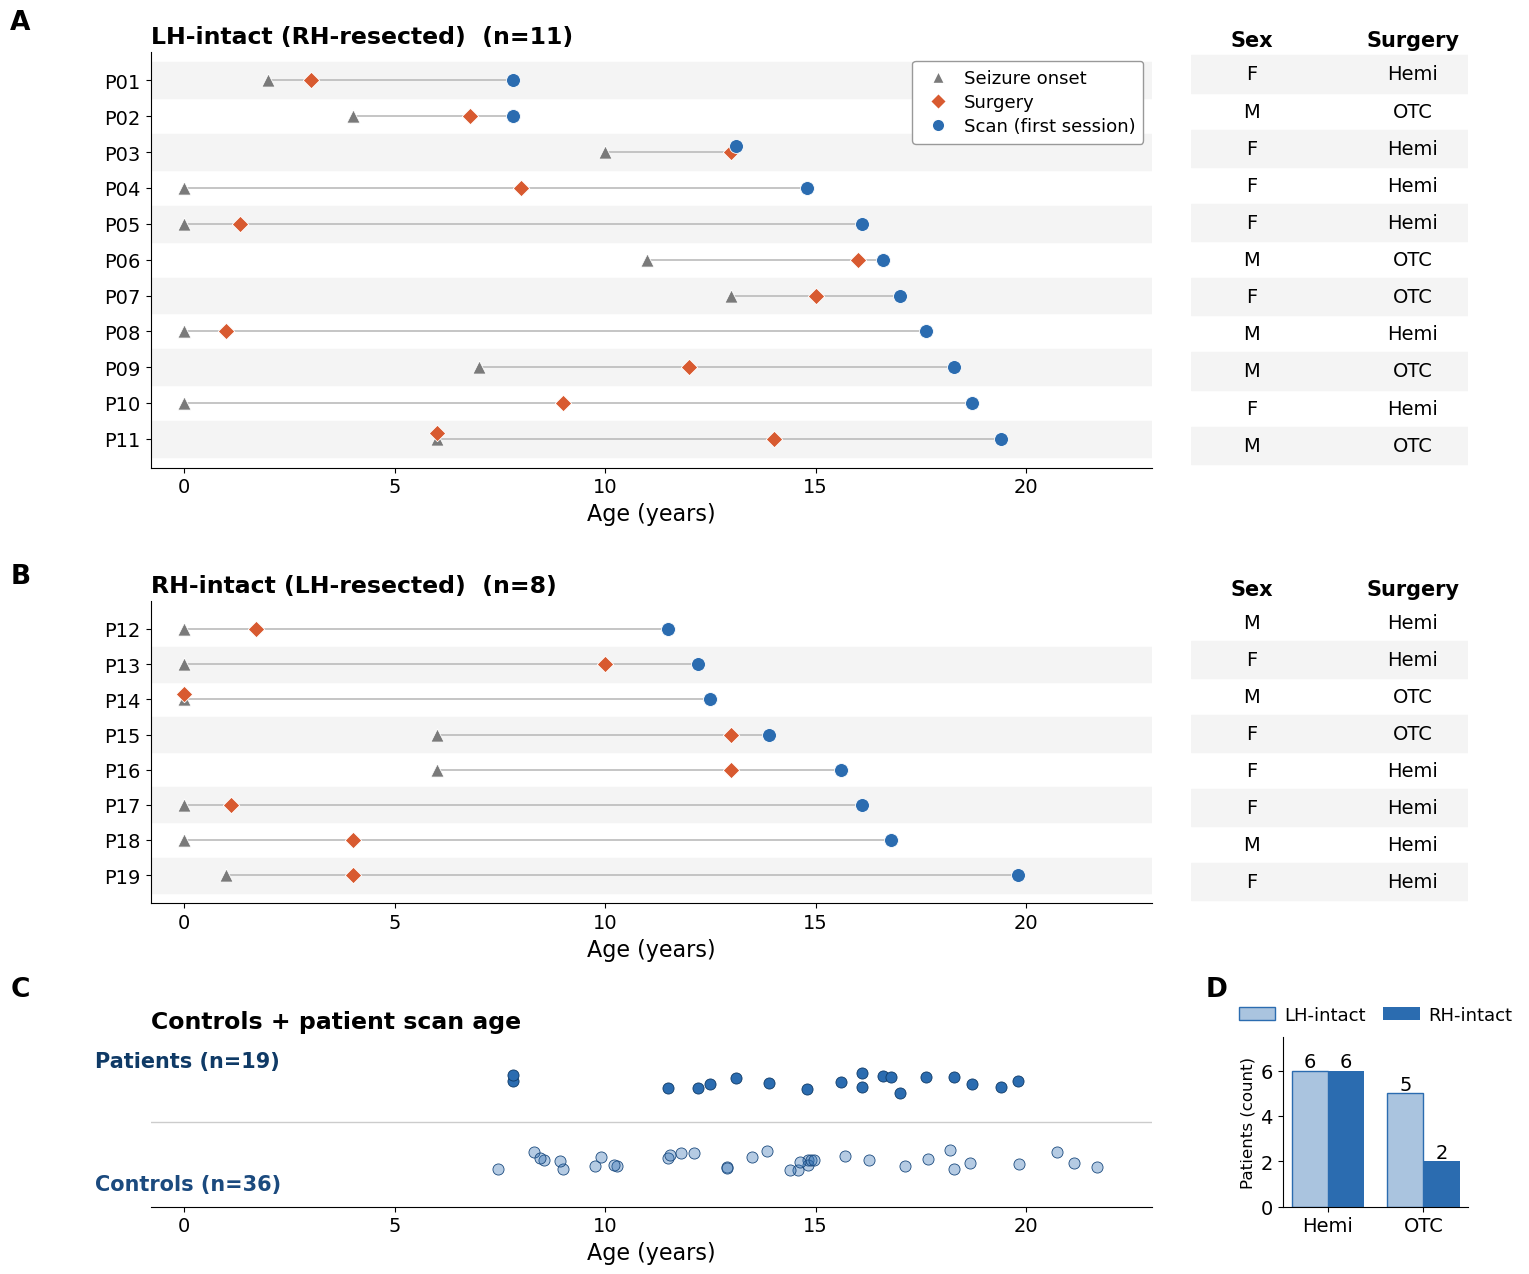

In [5]:
# ─── Figure 1: patient timelines, scan ages, surgery type ────────────────────
# Rows are the manuscript Figure 1 rows. Their P-numbers were renumbered after SI (key
# P13, over the age cap), so a figure P-number equals the key's for P01-P12 and is one
# lower from key P14 on. PATIENT_KEY maps every row to its subject; rows of excluded
# patients are dropped, the rest renumbered, and the mapping is saved to OUT.
from matplotlib import gridspec

PATIENT_KEY = pd.DataFrame([      # public_id, subject, code (patient key, from C.S. 2026-11-24)
    ('P01', 'sub-077', 'KI'), ('P02', 'sub-004', 'UD'), ('P03', 'sub-075', 'ED'), ('P04', 'sub-074', 'JD'),
    ('P05', 'sub-008', 'SF'), ('P06', 'sub-098', 'BI'), ('P07', 'sub-079', 'EC'), ('P08', 'sub-039', 'KQ'),
    ('P09', 'sub-109', 'XC'), ('P10', 'sub-089', 'ON'), ('P11', 'sub-101', 'BN'), ('P12', 'sub-005', 'KU'),
    ('P13', 'sub-091', 'SI'), ('P14', 'sub-099', 'KN'), ('P15', 'sub-069', 'NM'), ('P16', 'sub-044', 'SN'),
    ('P17', 'sub-010', 'FD'), ('P18', 'sub-021', 'TC'), ('P19', 'sub-090', 'KT'), ('P20', 'sub-076', 'JH'),
    ('P21', 'sub-108', 'EB'), ('P22', 'sub-066', 'JF'), ('P23', 'sub-092', 'FO'), ('P24', 'sub-082', 'KB'),
    ('P25', 'sub-078', 'IT')], columns=['public_id', 'subject_id', 'code'])
_n = PATIENT_KEY.public_id.str[1:].astype(int)
PATIENT_KEY['fig_pid'] = [None if k == 13 else f'P{(k if k < 13 else k - 1):02d}' for k in _n]
P2SUB = dict(PATIENT_KEY.dropna(subset=['fig_pid'])[['fig_pid', 'subject_id']].values)

CSV = str(SUB_INFO)

C_SCAN  = "#2B6CB0"
C_EDGE_C= "#1B4A7E"
C_EDGE_P= "#0F3A66"
C_SEIZ, C_SURG = "#7A7A7A", "#D85A30"
LINE, BAND = "#BBBBBB", "#F4F4F4"
C_LH_BAR = (0.169, 0.424, 0.690, 0.40)   # translucent C_SCAN
AGE_MAX = 23
rng = np.random.default_rng(7)

# (pid, sex, surgery, seizure, surgery_age, scan)
LH_ALL = [
    ("P01","F","Hemi",  2.0,  3.0,   7.8),
    ("P02","M","OTC",   4.0,  6.8,   7.8),   # = sub-004 (UD in Liu 2025); surgery 6y9m
    ("P03","F","OTC",   4.0,  4.0,  11.6),
    ("P04","F","Hemi", 10.0, 13.0,  13.1),
    ("P05","F","Hemi",  0.0,  8.0,  14.8),
    ("P06","F","Hemi",  0.0,  1.33, 16.11),
    ("P07","M","OTC",  11.0, 16.0,  16.6),
    ("P08","F","OTC",  13.0, 15.0,  17.0),
    ("P09","M","Hemi",  0.0,  1.0,  17.62),
    ("P10","M","OTC",   7.0, 12.0,  18.3),
    ("P11","F","Hemi",  0.0,  9.0,  18.71),
    ("P12","M","OTC",   6.0,(6.0,14.0),19.4),
]
RH_ALL = [
    ("P13","M","Hemi",  0.0,  1.7, 11.5),
    ("P14","F","Hemi",  0.0, 10.0, 12.2),
    ("P15","M","OTC",   0.0,  0.0, 12.5),
    ("P16","M","Hemi",  4.0,  7.0, 12.8),
    ("P17","F","OTC",   6.0, 13.0, 13.9),
    ("P18","F","Hemi",  6.0, 13.0, 15.6),
    ("P19","M","OTC",   0.0, 10.0, 16.1),
    ("P20","F","Hemi",  0.0,  1.1, 16.1),
    ("P21","M","Hemi",  0.0,  4.0, 16.8),
    ("P22","F","Hemi",  1.0,  4.0, 19.8),
    ("P23","M","OTC",  13.0, 18.0, 20.5),
    ("P24","F","OTC",  11.0, 17.0, 22.2),
]

_typ = {r[0]: r[2] for r in LH_ALL + RH_ALL}
_mism = [(p, P2SUB[p], t) for p, t in _typ.items()
         if (t == 'Hemi' and P2SUB[p] in LOBAR) or (t == 'OTC' and P2SUB[p] in HEMI)]
print('rows whose surgery type disagrees with HEMI/LOBAR:', _mism or 'none')
_drop = {p for p, s in P2SUB.items() if s in EXCLUDE_PATIENTS}
_missing = sorted(set(EXCLUDE_PATIENTS) - {P2SUB[p] for p in _drop})
FIG1_READY = not _missing
if FIG1_READY:
    LH = [r for r in LH_ALL if r[0] not in _drop]
    RH = [r for r in RH_ALL if r[0] not in _drop]
    _renum = {r[0]: f'P{i + 1:02d}' for i, r in enumerate(LH + RH)}
    LH = [(_renum[r[0]],) + tuple(r[1:]) for r in LH]
    RH = [(_renum[r[0]],) + tuple(r[1:]) for r in RH]
    print('dropped rows:', sorted(_drop), '| renumbered:', {k: v for k, v in _renum.items() if k != v})
    assert len(LH) == EXPECT['left'] and len(RH) == EXPECT['right'], (len(LH), len(RH))
    _map = PATIENT_KEY.dropna(subset=['fig_pid']).copy()
    _map['kept'] = ~_map.subject_id.isin(EXCLUDE_PATIENTS)
    _map['fig_pid_11_8'] = _map.fig_pid.map(_renum)
    _map.to_csv(OUT / 'fig1_rows_11-8.csv', index=False)
    assert set(_map[_map.kept].subject_id) == set(pt_ids), 'Figure 1 patients differ from the analysed cohort'
else:
    print('Figure 1 skipped. Find these patients in the patient key and add their rows to P2SUB:', _missing)
    LH, RH = LH_ALL, RH_ALL     # keeps the helpers below defined; nothing is drawn
PT_SCAN = np.array([r[5] for r in LH+RH])
assert PT_SCAN.max() <= AGE_CAP, "a patient is above the age cap"

# The plotted scan must follow at least one surgery. Patients with more than
# one operation (surgery_age given as a tuple) can legitimately have a later
# surgery after the scan, so the check is against the EARLIEST surgery.
_su = lambda v: [x for x in (list(v) if isinstance(v,(tuple,list)) else [v])
                 if x is not None]
_bad = [(r[0], _su(r[4]), r[5]) for r in LH+RH if min(_su(r[4])) > r[5]]
if _bad:
    print("WARNING scan precedes all recorded surgeries:",
          ", ".join(f"{p} surgery {s} > scan {c}" for p,s,c in _bad))
COLX = {"Sex":0.22, "Surgery":0.80}

FS_TICK=14; FS_CELL=14; FS_HEADER=15; FS_TITLE=17; FS_XLAB=16; FS_NLAB=15
FS_LETTER=19; FS_LEGEND=13; FS_DLAB=15


def bands(ax, n):
    for r in range(n):
        if r % 2 == 0: ax.axhspan(r-0.5, r+0.5, color=BAND, zorder=0)


def panel_letter(ax, L, dx=-0.12, dy=1.04):
    ax.text(dx, dy, L, transform=ax.transAxes, fontsize=FS_LETTER, fontweight="bold",
            va="bottom", ha="right")


def draw_timeline(ax, rows):
    """One row per patient. Events at the same age are offset vertically so
    seizure onset, surgery and scan do not overlap."""
    n=len(rows); bands(ax,n)
    JIT, WIN = 0.16, 0.6          # vertical offset; collision window in years
    for i,row in enumerate(rows):
        pid,_,_,sz,su,sc=row; y=n-1-i
        su_list=[v for v in (list(su) if isinstance(su,(tuple,list)) else [su])
                 if v is not None]
        ax.plot([min([sz]+su_list+[sc]), max([sz]+su_list+[sc])],[y,y],
                color=LINE,lw=1.2,zorder=1)
        ev = ([(sz,"^",90,C_SEIZ)]
              + [(sv,"D",70,C_SURG) for sv in su_list]
              + [(sc,"o",100,C_SCAN)])
        seen=[]
        for age,mk,ms,col in ev:
            k=sum(1 for a in seen if abs(a-age) < WIN); seen.append(age)
            dy = 0 if k==0 else (JIT if k % 2 else -JIT) * ((k+1)//2)
            ax.scatter(age, y+dy, marker=mk, s=ms, color=col, zorder=3,
                       edgecolors="white", linewidths=.6)
    ax.set_yticks(range(n)); ax.set_yticklabels([r[0] for r in reversed(rows)],fontsize=FS_TICK)
    ax.set_ylim(-0.8,n-0.2); ax.set_xlim(-0.8,AGE_MAX)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=FS_TICK)


def draw_table(ax, rows, header=False):
    n=len(rows); bands(ax,n); ax.set_xlim(0,1); ax.set_ylim(-0.6,n-0.4); ax.axis("off")
    for i,row in enumerate(rows):
        sex,surg=row[1],row[2]; y=n-1-i
        ax.text(COLX["Sex"],y,sex,ha="center",va="center",fontsize=FS_CELL)
        ax.text(COLX["Surgery"],y,surg,ha="center",va="center",fontsize=FS_CELL)
    if header:
        for label,x in COLX.items():
            ax.text(x,n-0.35,label,ha="center",va="bottom",fontsize=FS_HEADER,
                    fontweight="bold",clip_on=False)



def draw_strip(ax):
    cage = peak_c.drop_duplicates('subject_id')['age'].to_numpy(float)   # analysed controls, first session
    print(f'controls in the strip: {len(cage)}')
    ax.axhline(0,color="#CCCCCC",lw=1,zorder=0)
    ax.scatter(PT_SCAN,0.45+rng.uniform(-.12,.12,len(PT_SCAN)),s=64,color=C_SCAN,
               edgecolors=C_EDGE_P,linewidths=.6,zorder=3)
    ax.scatter(cage,-0.45+rng.uniform(-.12,.12,len(cage)),s=64,
               facecolors=(0.169,0.424,0.690,0.35),edgecolors=C_EDGE_C,
               linewidths=.6,zorder=3)
    ax.set_xlim(-0.8,AGE_MAX); ax.set_ylim(-1,1); ax.set_yticks([])
    ax.spines["top"].set_visible(False); ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=FS_TICK)
    ax.set_xlabel("Age (years)",fontsize=FS_XLAB)
    ax.text(-0.055,.82,"Patients (n=" + str(len(PT_SCAN)) + ")",transform=ax.transAxes,
            fontsize=FS_NLAB,color=C_EDGE_P,fontweight="bold")
    ax.text(-0.055,.10,"Controls (n=" + str(len(cage)) + ")",transform=ax.transAxes,
            fontsize=FS_NLAB,color=C_EDGE_C,fontweight="bold")


def draw_surgtype(ax):
    cats=["Hemi","OTC"]
    lh_c=[sum(r[2]==c for r in LH) for c in cats]
    rh_c=[sum(r[2]==c for r in RH) for c in cats]
    x=np.arange(len(cats)); w=0.38
    ax.bar(x-w/2,lh_c,w,label="LH-intact",color=C_LH_BAR,edgecolor=C_SCAN,linewidth=1.0)
    ax.bar(x+w/2,rh_c,w,label="RH-intact",color=C_SCAN)
    for xi,(a,b) in enumerate(zip(lh_c,rh_c)):
        ax.text(xi-w/2,a+0.15,a,ha="center",fontsize=FS_CELL)
        ax.text(xi+w/2,b+0.15,b,ha="center",fontsize=FS_CELL)
    ax.set_xticks(x); ax.set_xticklabels(cats,fontsize=FS_DLAB)
    ax.set_ylabel("Patients (count)",fontsize=FS_DLAB-3)
    ax.set_ylim(0, max(max(lh_c),max(rh_c))+1.5)
    ax.legend(fontsize=FS_LEGEND,frameon=False,loc="lower center",
              bbox_to_anchor=(0.5,0.98),ncol=2,columnspacing=1.0,handletextpad=0.5)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=FS_TICK)



if FIG1_READY:
    fig=plt.figure(figsize=(17,15))
    gs=gridspec.GridSpec(3,2,width_ratios=[13,3.6],
                         height_ratios=[len(LH),len(RH),4.5],wspace=0.06,hspace=0.45)

    axLm,axLt=fig.add_subplot(gs[0,0]),fig.add_subplot(gs[0,1])
    draw_timeline(axLm,LH); draw_table(axLt,LH,header=True)
    axLm.set_title("LH-intact (RH-resected)  (n=" + str(len(LH)) + ")",
                   fontsize=FS_TITLE,fontweight="bold",loc="left"); panel_letter(axLm,"A")
    axLm.set_xlabel("Age (years)",fontsize=FS_XLAB)

    axRm,axRt=fig.add_subplot(gs[1,0]),fig.add_subplot(gs[1,1])
    draw_timeline(axRm,RH); draw_table(axRt,RH,header=True)
    axRm.set_title("RH-intact (LH-resected)  (n=" + str(len(RH)) + ")",
                   fontsize=FS_TITLE,fontweight="bold",loc="left"); panel_letter(axRm,"B")
    axRm.set_xlabel("Age (years)",fontsize=FS_XLAB)

    axSm=fig.add_subplot(gs[2,0])
    draw_strip(axSm)
    axSm.set_title("Controls + patient scan age",fontsize=FS_TITLE,fontweight="bold",loc="left")
    panel_letter(axSm,"C",dy=1.20)

    ndg=gs[2,1].subgridspec(1,2,width_ratios=[4.0,8],wspace=0)
    axD=fig.add_subplot(ndg[0,1]); draw_surgtype(axD)
    panel_letter(axD,"D",dx=-0.30,dy=1.20)

    handles=[
        plt.Line2D([],[],marker="^",color="w",markerfacecolor=C_SEIZ,ms=10,label="Seizure onset"),
        plt.Line2D([],[],marker="D",color="w",markerfacecolor=C_SURG,ms=9,label="Surgery"),
        plt.Line2D([],[],marker="o",color="w",markerfacecolor=C_SCAN,ms=10,label="Scan (first session)"),
    ]
    axLm.legend(handles=handles, loc="upper right", ncol=1, fontsize=FS_LEGEND,
                frameon=True, edgecolor="#999999", framealpha=1.0,
                borderpad=0.45, labelspacing=0.35, handletextpad=0.4, markerscale=0.9)
    plt.savefig(FIG_DIR / 'fig1_patients_11-8.png', dpi=300, bbox_inches='tight')
    plt.show()


## 2 · Statistics: the paper's stats script, this cohort

In [6]:
# ─── Statistics: the paper's stats script, run unchanged for this cohort ─────
# Same approach as sandbox/sens_anterior_temporal.py: a fresh module, with inputs,
# EXCLUDE / EXCLUDE_SES and output paths set from outside. The mixed models need
# statsmodels (fmri env). TFCE is not rerun for this cohort; WTA runs only if its rerun
# input exists. Ages come from this notebook's sub_info.
print('stats script md5:', hashlib.md5(STATS_PY.read_bytes()).hexdigest(),
      '(record run used dd4843b9257b15356dbcb3c9e6aed23f)')
_spec = importlib.util.spec_from_file_location('stats_11_8', STATS_PY)
S = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(S)
S.UNIVAR_CSV, S.RSA_CSV = UNIVAR_SQRT, RSA_HARM
S.PEAK_MNI = RERUN_MORE / 'peaks_P2_nosmooth_c20.csv'
S.WTA_CSV = RERUN_MORE / 'wta_nosmooth.csv'
S.EXCLUDE, S.EXCLUDE_SES = list(EXCLUDE), list(EXCLUDE_SES)
S.OUT_RESULTS, S.OUT_TFCE = STATS_CSV, OUT / 'tfce_not_rerun.csv'
S.tfce_clusters = lambda: pd.DataFrame()
_ages = (si[['sub', 'ses_num', 'age']].rename(columns={'sub': 'subject_id'})
         .dropna().drop_duplicates(['subject_id', 'ses_num']))
_ages['ses_num'] = _ages['ses_num'].astype('Int64')
S._age_table = lambda: _ages
if not Path(S.WTA_CSV).exists():
    print('WTA input missing -> WTA rows skipped')
    S.wta_composition = lambda results, fdr_method='bh': None
_argv, sys.argv = sys.argv, [str(STATS_PY)]          # inputs are set on the module, as in sens_anterior_temporal.py
try:
    with open(OUT / 'stats_log_11-8.txt', 'w') as _log, contextlib.redirect_stdout(_log):
        S.main()
finally:
    sys.argv = _argv
STATS = pd.read_csv(STATS_CSV)
print(f'{len(STATS)} rows -> {STATS_CSV}')
print('omnibus rows with a value:', int(STATS['omnibus_p'].notna().sum()),
      '(0 means statsmodels was unavailable)')


stats script md5: dd4843b9257b15356dbcb3c9e6aed23f (record run used dd4843b9257b15356dbcb3c9e6aed23f)


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/statsmodels/regression/mi

274 rows -> /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/stats_results_11-8.csv
omnibus rows with a value: 32 (0 means statsmodels was unavailable)


In [7]:
# ─── Key results, in the paper's four-comparison order ───────────────────────
# Reads each row the way the paper does: q for per-ROI families, p for the
# mean-over-ROIs effects, omnibus p for omnibus rows.
def _crit(r):
    if r.comparison == 'omnibus':
        return r.omnibus_p, 'omnibus p'
    if str(r.level).startswith('MEAN_OVER') or pd.isna(r.q_fdr):
        return r.p_perm, 'p'
    return r.q_fdr, 'q'

ORDER = [('controls, left vs right', 'ctrl_LvsR'),
         ('LH-intact vs left controls', 'LH-intact_pt_vs_ctrl'),
         ('RH-intact vs right controls', 'RH-intact_pt_vs_ctrl'),
         ('LH-intact vs RH-intact', 'pt_LH_vs_RH')]
_rows = []
for meas in ['peak_selectivity', 'selective_voxels', 'distinctiveness', 'geometry']:
    d = STATS[STATS['measure'] == meas]
    for lab, key in ORDER:
        sub = d[d['model'].astype(str).str.endswith(key)] if meas == 'geometry' else d[d['model'] == key]
        for r in sub.itertuples():
            v, kind = _crit(r)
            _rows.append(dict(measure=meas, comparison=lab, model=r.model, test=r.comparison,
                              level=r.level, d=r.cohens_d, value=v, kind=kind,
                              significant=(v < .05) if pd.notna(v) else None))
KEY = pd.DataFrame(_rows)
KEY.to_csv(OUT / 'key_results_11-8.csv', index=False)
with pd.option_context('display.max_rows', 400, 'display.width', 220):
    print(KEY[KEY['significant'] == True].round(3).to_string(index=False))
print(f"\n{int((KEY['significant'] == True).sum())} significant of {len(KEY)} rows; "
      f"full table: {OUT / 'key_results_11-8.csv'}")


         measure                  comparison                           model               test            level      d  value      kind  significant
peak_selectivity     controls, left vs right                       ctrl_LvsR  control_asymmetry house_PPA_strict -0.366  0.044         q         True
peak_selectivity     controls, left vs right                       ctrl_LvsR  control_asymmetry       object_LOC  0.421  0.039         q         True
peak_selectivity     controls, left vs right                       ctrl_LvsR  control_asymmetry        word_VWFA  0.755  0.000         q         True
peak_selectivity     controls, left vs right                       ctrl_LvsR  group_main_effect   MEAN_OVER_ROIS  0.382  0.027         p         True
peak_selectivity     controls, left vs right                       ctrl_LvsR            omnibus              ALL    NaN  0.000 omnibus p         True
peak_selectivity  LH-intact vs left controls            LH-intact_pt_vs_ctrl patient_vs_control     

## 3 · ROI figures

In [8]:
# ─── Shared box-panel renderer for §5, §6, §7 ────────────────────────────
# From 01_final_figures, unchanged except the last two lines, which save each figure
# to FIG_DIR (the original only displayed it).
# box = IQR, bar = mean, no whiskers, every subject drawn as an open circle.
# Whiskers are dropped because all points are plotted, so the range is already
# on the page; the box is the IQR rather than a CI of the mean, since a
# whiskerless box is read as a quantile.
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

MIN_N = 3
BRACKET_L0, BRACKET_STEP, BRACKET_PAD = 0.06, 0.11, 0.09   # fractions of panel span


def q_sets(measure, verbose=True):
    """(patient_vs_control, control_asymmetry, patient_subgroup) q dicts."""
    d = STATS[STATS['measure'] == measure]
    pvc = {(r.level, r.hemi): r.q_fdr
           for r in d[d['comparison'] == 'patient_vs_control'].itertuples()}
    casy = {r.level: r.q_fdr
            for r in d[d['comparison'] == 'control_asymmetry'].itertuples()}
    psub = {r.level: r.q_fdr
            for r in d[d['comparison'] == 'patient_subgroup'].itertuples()}
    if verbose:
        print(f'{measure}: q cells pt-vs-ctrl {len(pvc)}/8, '
              f'ctrl asym {len(casy)}/4, pt subgroup {len(psub)}/4')
        if not pvc:
            print(f"  no measure == '{measure}' rows in STATS_CSV"
                  f' -> panels draw without stars')
    return pvc, casy, psub


def slot_vals(ctrl_df, pt_df, col):
    """Build the f(roi, slot, hemi) -> array that panel_row() consumes."""
    def f(roi, slot, hemi):
        if slot.startswith('ctrl'):
            d = ctrl_df[(ctrl_df['category'] == roi) & (ctrl_df['hemi'] == hemi)]
        else:
            intact = 'left' if hemi == 'l' else 'right'
            d = pt_df[(pt_df['category'] == roi) & (pt_df['intact_hemi'] == intact)]
        return d[col].dropna().values
    return f


def panel_row(get_vals, rois, ylabel, fname, q_pvc, q_casy, q_psub,
              own_scale=(), zero_line=False, seed=0, ydecimals=None,
              legend=True, legend_loc='upper left', legend_xy=(0.02, 0.985),
              pt_size=55, box_w=0.34, jit=0.055, dpi=200):
    """One row of category panels, slots in SLOTS order (ctrl L, pt L, ctrl R, pt R).

    Fill alpha encodes group, per the key above the first panel; hemisphere is
    labelled by the LH/RH tier under the axis. Dashed bracket = patient vs
    matched-hemisphere control, now adjacent slots. Solid brackets = left vs right within controls,
    then within patients; those two span each other in x, so they stack.
    A bracket level is only reserved if that comparison is significant somewhere
    in the row, so a row with no stars keeps its full plotting height.

    own_scale  ROIs given their own y limits instead of the shared ones
    zero_line  draw a rule at y = 0
    ydecimals  decimals on the y tick labels; None picks 0 when the panel
               spans >= 5 units and 1 otherwise, so a -0.5-1.5 scale does
               not collapse to three integer ticks
    """
    rois = [r for r in rois
            if len(get_vals(r, 'ctrl L', 'l')) or len(get_vals(r, 'ctrl R', 'r'))]
    print('panels:', [ROI_TITLE.get(r, r) for r in rois])
    for r in rois:
        print(' ', ROI_TITLE.get(r, r),
              {s[0]: len(get_vals(r, s[0], s[2])) for s in SLOTS})

    def pool(rs):
        v = np.concatenate([get_vals(r, s[0], s[2]) for r in rs for s in SLOTS
                            if len(get_vals(r, s[0], s[2])) >= MIN_N])
        lo, hi = float(v.min()), float(v.max())
        return lo, hi, (hi - lo) or 1.0

    shared = [r for r in rois if r not in own_scale]
    lims = {r: pool(shared) for r in shared}
    lims.update({r: pool([r]) for r in rois if r in own_scale})

    # reserve a bracket level only for families that are significant somewhere
    lv, nxt = {}, 0
    for kind, present in (
            ('pvc', any(stars(q_pvc.get((r, h))) for r in rois for h in ('l', 'r'))),
            ('casy', any(stars(q_casy.get(r)) for r in rois)),
            ('psub', any(stars(q_psub.get(r)) for r in rois))):
        if present:
            lv[kind] = nxt
            nxt += 1

    rng = np.random.RandomState(seed)
    wsp = 0.10 if any(r in own_scale for r in rois) else 0.04
    fig, axes = plt.subplots(1, len(rois), figsize=(4.4 * len(rois), 7.8),
                             sharey=False, gridspec_kw={'wspace': wsp})
    axes = np.atleast_1d(axes)
    fig.patch.set_facecolor('white')

    for i, (ax, roi) in enumerate(zip(axes, rois)):
        base = CAT_COLORS[ROI_CAT[roi]]
        dark = shade(base, 0.62)
        gmin, gmax, span = lims[roi]
        ax.set_facecolor('white')
        ax.yaxis.grid(True, color='#ededed', lw=0.8)
        ax.set_axisbelow(True)
        if zero_line:
            ax.axhline(0, color='#999', lw=0.9)
        ax.axvline(HEMI_DIV, color='#ddd', lw=0.9, ls=':')    # LH | RH divider

        xs = {}
        for slot, xpos, hemi, alpha in SLOTS:
            v = get_vals(roi, slot, hemi)
            if len(v) < MIN_N:
                continue
            xs[slot] = xpos
            q1, q3 = np.percentile(v, [25, 75])
            m = v.mean()
            ax.add_patch(plt.Rectangle((xpos - box_w / 2, q1), box_w, q3 - q1,
                                       facecolor=base, alpha=alpha,
                                       edgecolor=dark, lw=0.9, zorder=2))
            ax.plot([xpos - box_w / 2, xpos + box_w / 2], [m, m],
                    color=dark, lw=2.0, zorder=4)
            ax.scatter(xpos + rng.uniform(-jit, jit, len(v)), v, s=pt_size,
                       facecolors='none', edgecolors=base, linewidths=1.1,
                       alpha=0.85, zorder=3)

        def bracket(x0, x1, s, kind, ls):
            yb = gmax + (BRACKET_L0 + BRACKET_STEP * lv[kind]) * span
            ax.plot([x0, x0, x1, x1],
                    [yb - 0.014 * span, yb, yb, yb - 0.014 * span],
                    color=dark, lw=1.4, ls=ls, alpha=0.9, zorder=5, clip_on=False)
            ax.text((x0 + x1) / 2, yb + 0.004 * span, s, ha='center', va='bottom',
                    fontsize=19, color=dark, fontweight='bold', clip_on=False)

        for hemi, cs, ps in (('l', 'ctrl L', 'pt L'), ('r', 'ctrl R', 'pt R')):
            s = stars(q_pvc.get((roi, hemi)))
            if s and 'pvc' in lv and cs in xs and ps in xs:
                bracket(xs[cs], xs[ps], s, 'pvc', '--')
        for kind, a, b, qv in (('casy', 'ctrl L', 'ctrl R', q_casy.get(roi)),
                               ('psub', 'pt L', 'pt R', q_psub.get(roi))):
            s = stars(qv)
            if s and kind in lv and a in xs and b in xs:
                bracket(xs[a], xs[b], s, kind, '-')

        head = ((BRACKET_L0 + BRACKET_STEP * max(lv.values()) + BRACKET_PAD)
                if lv else 0.05)
        ax.set_ylim(gmin - 0.05 * span, gmax + head * span)

        # x axis carries hemisphere only; group is in the key above panel 1
        ax.set_xticks([])
        tr = ax.get_xaxis_transform()
        for lab, x0, x1 in (('LH', SLOTS[0][1], SLOTS[1][1]),
                            ('RH', SLOTS[2][1], SLOTS[3][1])):
            ax.plot([x0, x1], [-0.028, -0.028], transform=tr,
                    color='#bbb', lw=0.9, clip_on=False)
            ax.text((x0 + x1) / 2, -0.048, lab, transform=tr, ha='center', va='top',
                    fontsize=17, fontweight='bold', color='#555', clip_on=False)

        nd = ydecimals if ydecimals is not None else (0 if span >= 5 else 1)
        if nd == 0:
            ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{nd}f'))
        ax.tick_params(axis='y', labelsize=19, length=4)
        ax.set_title(ROI_TITLE.get(roi, roi), fontsize=27, fontweight='bold',
                     color=dark, pad=20)
        ax.add_patch(plt.Rectangle((0.0, 1.015), 1.0, 0.017, color=base,
                                   transform=ax.transAxes, clip_on=False, lw=0))
        ax.set_xlim(*SLOT_XLIM)
        ax.spines['left'].set_color('#999')
        ax.spines['bottom'].set_color('#999')
        if i > 0 and lims[roi] == lims[rois[i - 1]]:
            ax.spines['left'].set_visible(False)
            ax.tick_params(axis='y', length=0, labelleft=False)

    axes[0].set_ylabel(ylabel, fontsize=21)

    # Compact group key above the first panel. Everything else - box = IQR,
    # bar = mean, solid bracket = left vs right, dashed = patient vs
    # matched-hemisphere control - belongs in the figure caption.    
    if legend:
        axes[0].legend(handles=[Patch(facecolor='#888', alpha=0.50, edgecolor='#777',
                                      lw=0.8, label='Control'),
                                Patch(facecolor='#888', alpha=0.20, edgecolor='#777',
                                      lw=0.8, label='Patient (intact hemi)')],
                       loc=legend_loc, bbox_to_anchor=legend_xy,
                       frameon=True, framealpha=0.95, edgecolor='#bbb',
                       fontsize=15, handlelength=1.8,
                       borderpad=0.6, labelspacing=0.4)
    fig.savefig(FIG_DIR / fname.replace('.png', '_11-8.png'), dpi=dpi, bbox_inches='tight')
    print('saved', FIG_DIR / fname.replace('.png', '_11-8.png'))


### Peak selectivity

peak_selectivity: q cells pt-vs-ctrl 8/8, ctrl asym 4/4, pt subgroup 4/4
panels: ['VWFA', 'FFA', 'PPA', 'LO']
  VWFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  FFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  PPA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  LO {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/figures/peak_selectivity_11-8.png


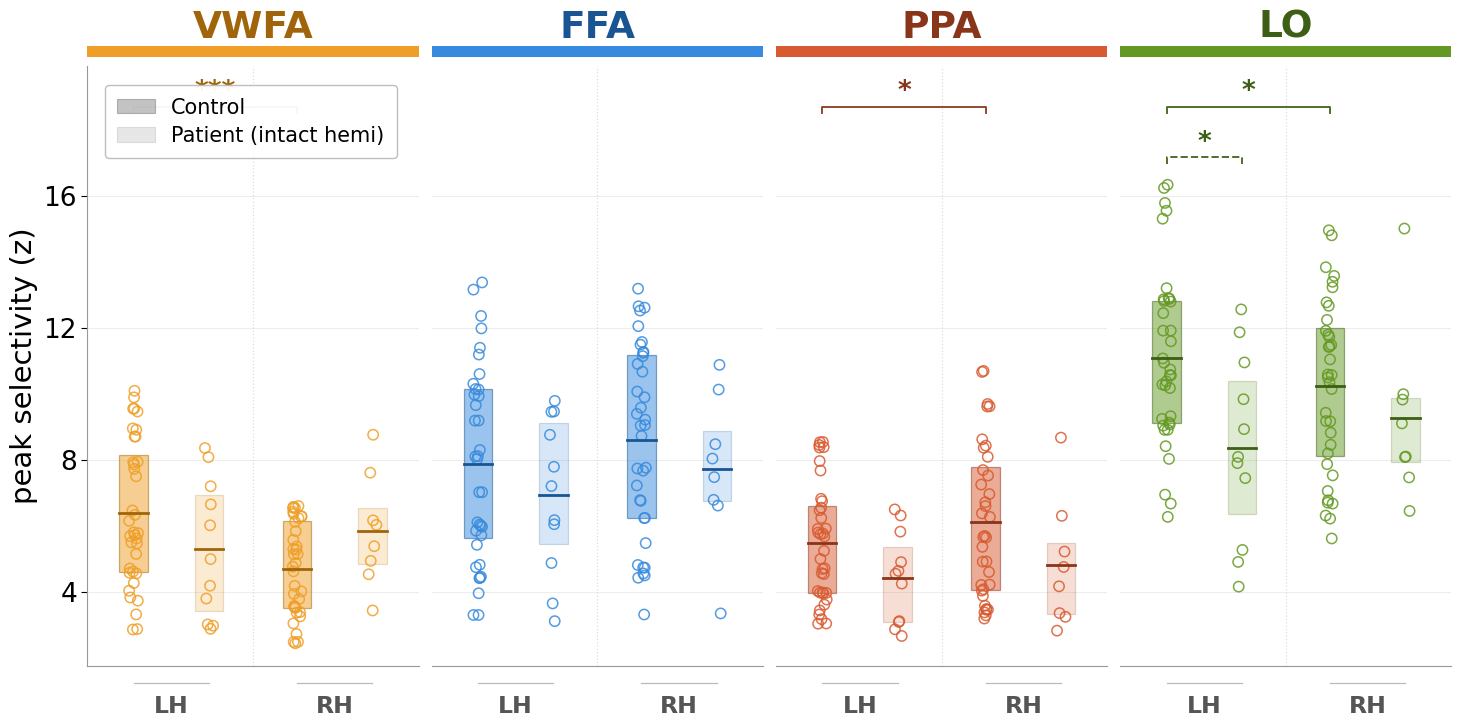

In [9]:
# ─── Peak selectivity ────────────────────────────────────────────────────
Q_PVC_PK, Q_CASY_PK, Q_PSUB_PK = q_sets('peak_selectivity')

panel_row(get_vals=slot_vals(peak_c, peak_p, 'peak_z'),
          rois=ROI_ORDER,
          ylabel='peak selectivity (z)',
          fname='peak_selectivity.png',
          q_pvc=Q_PVC_PK, q_casy=Q_CASY_PK, q_psub=Q_PSUB_PK)

### Number of category-selective voxels

selective_voxels: q cells pt-vs-ctrl 8/8, ctrl asym 4/4, pt subgroup 4/4
panels: ['VWFA', 'FFA', 'PPA', 'LO']
  VWFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  FFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  PPA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  LO {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/figures/selective_voxels_11-8.png


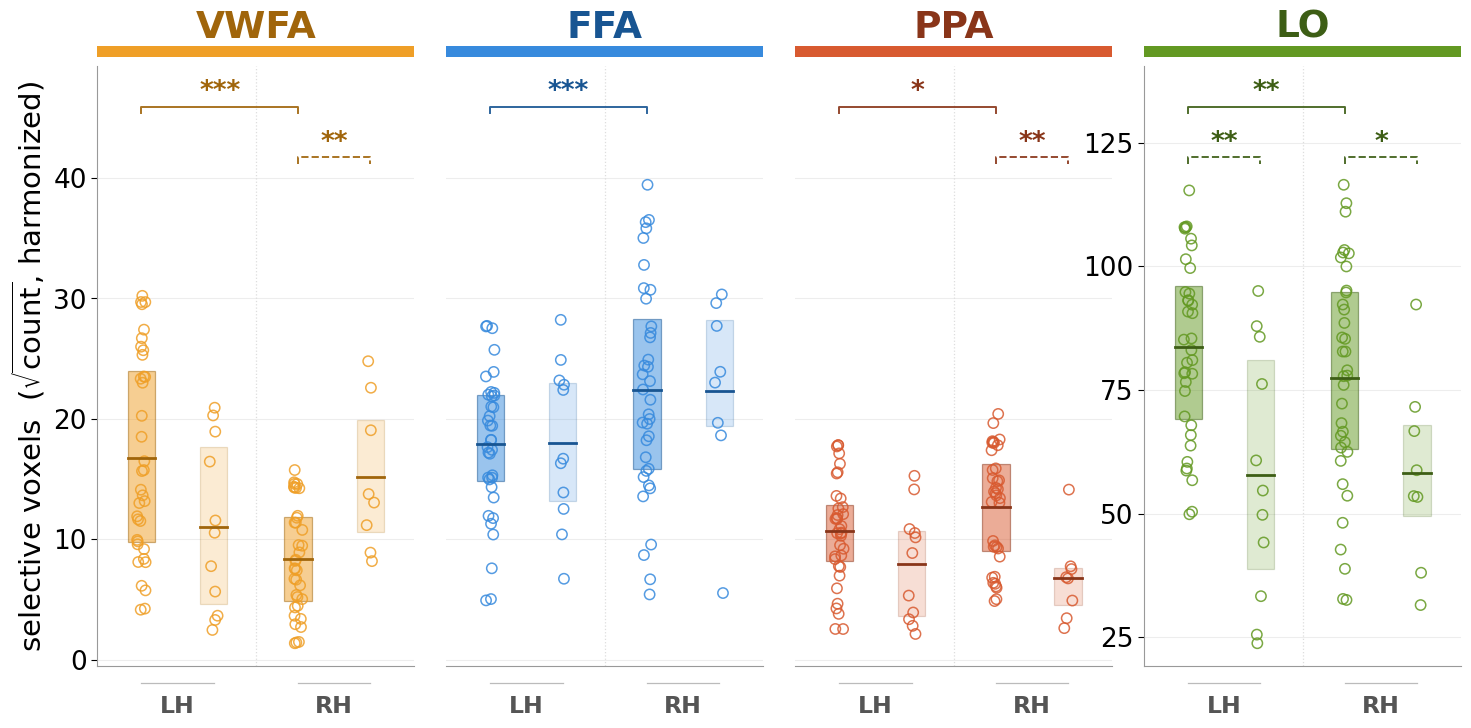

In [10]:
# ─── Number of category-selective voxels ─────────────────────────────────
Q_PVC_VX, Q_CASY_VX, Q_PSUB_VX = q_sets('selective_voxels')

panel_row(get_vals=slot_vals(vox_c, vox_p, 'volume'),
          rois=ROI_ORDER,
          ylabel='selective voxels  ($\\sqrt{\\mathrm{count}}$, harmonized)',
          fname='selective_voxels.png',
          q_pvc=Q_PVC_VX, q_casy=Q_CASY_VX, q_psub=Q_PSUB_VX,
          own_scale={'object_LOC'},
          legend=False)

### Preferred-category similarity

distinctiveness: q cells pt-vs-ctrl 8/8, ctrl asym 4/4, pt subgroup 4/4
panels: ['VWFA', 'FFA', 'PPA', 'LO']
  VWFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  FFA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  PPA {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
  LO {'ctrl L': 36, 'pt L': 11, 'ctrl R': 36, 'pt R': 8}
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/figures/preferred_category_similarity_11-8.png


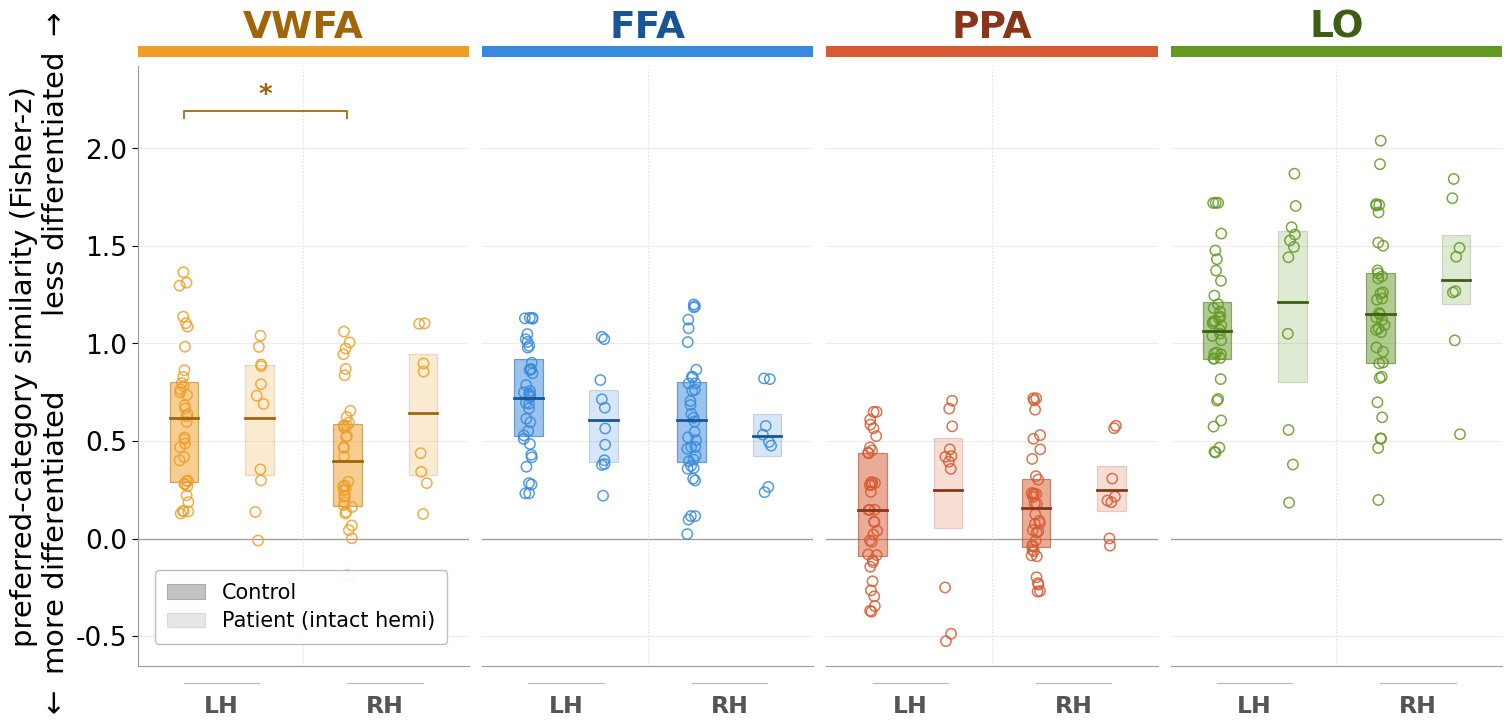

In [11]:
# ─── Preferred-category similarity ───────────────────────────────────────
Q_PVC, Q_CASY, Q_PSUB = q_sets('distinctiveness')

panel_row(get_vals=slot_vals(rsa_c, rsa_p, 'liu_distinctiveness'),
          rois=ROI_ORDER,
          ylabel='preferred-category similarity (Fisher-z)\n'
                 '$\\leftarrow$ more differentiated'
                 '        less differentiated $\\rightarrow$',
          fname='preferred_category_similarity.png',
          q_pvc=Q_PVC, q_casy=Q_CASY, q_psub=Q_PSUB,
          zero_line=True,
          legend_loc='lower left', legend_xy=(0.02, 0.02))

### Between-category similarity

patients vs patients, arrangement omnibus p: {'VWFA': 0.209, 'FFA': 0.415, 'PPA': 0.962, 'LO': 0.353}


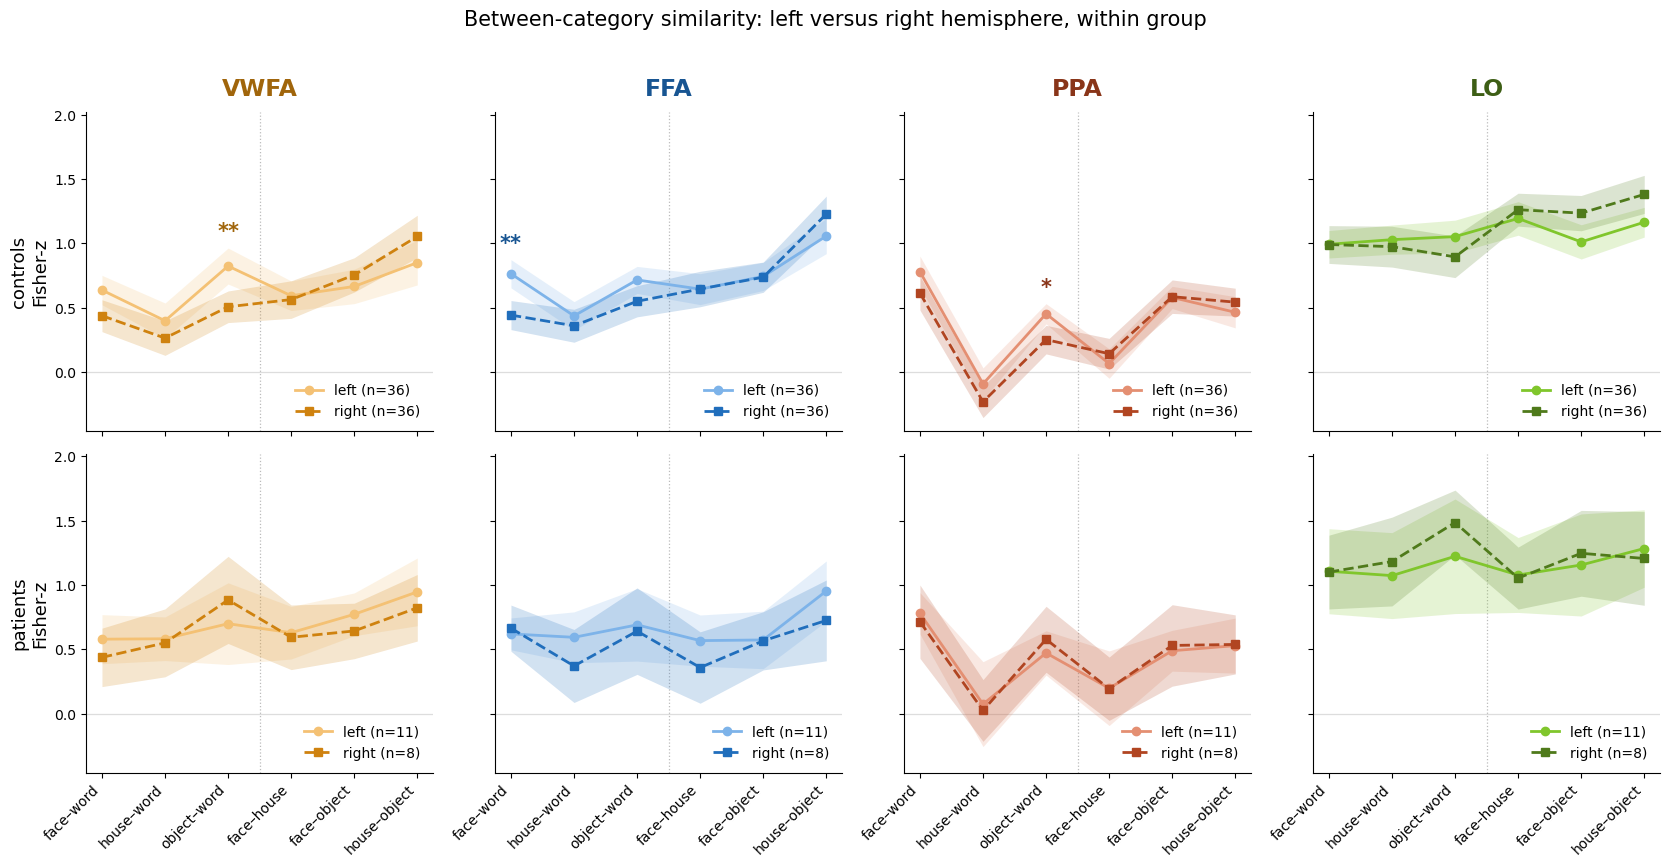

In [12]:
# ─── Between-category similarity: hemispheres within group ───────────────
# Row 1: control left vs control right. Row 2: LH-intact vs RH-intact patients.
# Same axes, so the two rows are directly comparable: controls separate,
# patients overlap.
#
# Asterisks on row 1 come from the control_asymmetry rows of the stats file.
# Row 2 cannot: 05_stats_harmony.py does not fit the patient-subgroup model for
# geometry, so STATS has no patient_subgroup geometry rows. Its values are computed
# below for this cohort. Only ROIs whose pt-vs-pt omnibus is significant are marked.

_gg = STATS[STATS['measure'] == 'geometry']
Q_CASY_PAIR = {(r.model.replace('_ctrl_LvsR', ''), r.level): r.q_fdr
               for r in _gg[_gg['model'].str.endswith('ctrl_LvsR')].itertuples()}
OMNI_CASY = {r.model.replace('_ctrl_LvsR', ''): r.omnibus_p
             for r in _gg[(_gg['model'].str.endswith('ctrl_LvsR')) &
                          (_gg['comparison'] == 'omnibus')].itertuples()}

# Row 2 (patients): the stats script fits no patient-subgroup geometry model, so it is
# computed here with the stats script's own functions: pair x intact-side mixed model
# (+ age, subject intercept), joint Wald chi2; pairs opened only where that omnibus is
# significant, two-tailed label-shuffle permutation, BH-FDR across the six pairs.
_H = S
if not all(hasattr(S, n) for n in ('lmm_omnibus', 'perm_independent', 'fdr_bh_by')):
    _sp = importlib.util.spec_from_file_location('stats_helpers', ROOT / 'pipeline/4_analyses/02_stats_harmony.py')
    _H = importlib.util.module_from_spec(_sp); _sp.loader.exec_module(_H)
OMNI_PTPT, Q_PTPT_PAIR = {}, {}
for _roi in ROI_ORDER:
    _d = rsa_p_long[rsa_p_long['category'] == _roi].dropna(subset=['fisher_r']).copy()
    _W, _df, _p, _ = _H.lmm_omnibus(_d, 'fisher_r', 'pair', 'intact_hemi', with_age=True)
    OMNI_PTPT[_roi] = _p
    if pd.notna(_p) and _p < .05:
        _ps = [_H.perm_independent(_d[(_d.pair == pr) & (_d.intact_hemi == 'left')].fisher_r.values,
                                  _d[(_d.pair == pr) & (_d.intact_hemi == 'right')].fisher_r.values)[1]
               for pr in PAIRS_ORDERED]
        _q, _ = _H.fdr_bh_by(_ps, 'bh')
        Q_PTPT_PAIR.update({(_roi, pr): qi for pr, qi in zip(PAIRS_ORDERED, _q)})
print('patients vs patients, arrangement omnibus p:',
      {ROI_TITLE[r]: (round(v, 3) if pd.notna(v) else None) for r, v in OMNI_PTPT.items()})

ROWS_WITHIN = [
    ('controls',
     lambda roi, h: rsa_c_long[(rsa_c_long['category'] == roi) &
                               (rsa_c_long['hemi'] == h)],
     OMNI_CASY, Q_CASY_PAIR),
    ('patients',
     lambda roi, h: rsa_p_long[(rsa_p_long['category'] == roi) &
                               (rsa_p_long['intact_hemi'] == ('left' if h == 'l' else 'right')) &
                               (rsa_p_long['hemi'] == h)],
     OMNI_PTPT, Q_PTPT_PAIR),
]
HEMI_STYLE = {'l': dict(ls='-',  marker='o', lab='left'),
              'r': dict(ls='--', marker='s', lab='right')}
HEMI_SHADE = {'l': 1.30, 'r': 0.80}

ROIS_LN = [r for r in ROI_ORDER if r in set(rsa_c_long['category'])]
x = np.arange(len(PAIRS_ORDERED))
n_word = sum('word' in p for p in PAIRS_ORDERED)

fig, axes = plt.subplots(len(ROWS_WITHIN), len(ROIS_LN),
                         figsize=(4.2 * len(ROIS_LN), 4.4 * len(ROWS_WITHIN)),
                         sharey=True, sharex=True)
axes = np.atleast_2d(axes)
fig.patch.set_facecolor('white')

for r, (rlab, sel, omni, qpair) in enumerate(ROWS_WITHIN):
    for c, roi in enumerate(ROIS_LN):
        ax = axes[r, c]
        base = CAT_COLORS[ROI_CAT[roi]]
        ax.set_facecolor('white')
        ax.axhline(0, color='#ddd', lw=0.9, zorder=0)
        ax.axvline(n_word - 0.5, color='#bbb', lw=0.9, ls=':', zorder=0)
        hi_by_hemi = {}
        for h in ('l', 'r'):
            d = sel(roi, h)
            m, lo, hi, nn = [], [], [], []
            for pair in PAIRS_ORDERED:
                v = d[d['pair'] == pair]['fisher_r'].dropna().values
                if len(v) < 3:
                    m.append(np.nan); lo.append(np.nan); hi.append(np.nan)
                    continue
                mu = v.mean(); half = 1.96 * v.std(ddof=1) / np.sqrt(len(v))
                m.append(mu); lo.append(mu - half); hi.append(mu + half)
                nn.append(len(v))
            m, lo, hi = map(np.array, (m, lo, hi))
            hi_by_hemi[h] = hi
            col = shade(base, HEMI_SHADE[h])
            st = HEMI_STYLE[h]
            ax.fill_between(x, lo, hi, color=col, alpha=0.20, lw=0, zorder=1)
            ax.plot(x, m, color=col, lw=2.0, ls=st['ls'], marker=st['marker'],
                    ms=6, zorder=2,
                    label=f"{st['lab']} (n={max(nn) if nn else 0})")

        # asterisk just above the taller of the two CIs at that pair
        if omni.get(roi, 1) < .05:
            top = np.nanmax(np.vstack([hi_by_hemi['l'], hi_by_hemi['r']]), axis=0)
            for i, pair in enumerate(PAIRS_ORDERED):
                s_ = stars(qpair.get((roi, pair)))
                if s_ and np.isfinite(top[i]):
                    ax.text(i, top[i] + 0.05, s_, ha='center', va='bottom',
                            fontsize=15, fontweight='bold',
                            color=shade(base, 0.62), clip_on=False)

        if r == 0:
            ax.set_title(ROI_TITLE.get(roi, roi), fontsize=17,
                         fontweight='bold', color=shade(base, 0.62), pad=12)
        if c == 0:
            ax.set_ylabel(f'{rlab}\nFisher-z', fontsize=13)
        ax.legend(frameon=False, fontsize=10, loc='lower right')
        ax.set_xticks(x)
        ax.set_xticklabels([p.replace('-', '\u2013') for p in PAIRS_ORDERED],
                           rotation=45, ha='right', fontsize=10)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)

# headroom so the asterisks stay inside the axes
axes[0, 0].set_ylim(top=axes[0, 0].get_ylim()[1] + 0.18)

fig.suptitle('Between-category similarity: left versus right hemisphere, within group',
             fontsize=15, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / 'between_category_within_group_11-8.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()

## 4 · Whole OTC, ventral parcel

In [13]:
# ─── Whole-OTC test functions: wotc.py, unchanged except two names ─────────────
# From chat_scripts_2026-11-16 (wotc/wotc.py), the code behind the docx whole-OTC values
# (it reproduces separation p = .027 for the full cohort). load -> wotc_load and
# stats -> wotc_stats and bf10_jzs -> wotc_bf10_jzs, so they do not shadow other names.
"""Whole-OTC statistics for V3's paragraphs, ported from sandbox_removals_v2.ipynb cells 10 (arrangement, consistency,
typicality BF), 14 (agreement), 24 (spread); plus reconstructions (validated against V3 on the record) of the
control typicality BF/p, the six-value mean BF, the within- vs across-side contrast, and the whole-OTC face-word test."""
import numpy as np, pandas as pd
from scipy import integrate
def _zc(M): return (M - M.mean(1, keepdims=True)) / M.std(1, ddof=0, keepdims=True)
def wotc_bf10_jzs(x, r=0.707):
    x = np.asarray(x, float); t, n = x.mean() / (x.std(ddof=1) / np.sqrt(len(x))), len(x); v = n - 1
    num = lambda g: ((1 + n * g) ** -0.5 * (1 + t ** 2 / ((1 + n * g) * v)) ** (-(v + 1) / 2) * (r ** 2 / 2) ** 0.5 / np.sqrt(np.pi) * g ** -1.5 * np.exp(-r ** 2 / (2 * g)))
    return integrate.quad(num, 0, np.inf)[0] / (1 + t ** 2 / v) ** (-(v + 1) / 2)
def wotc_load(csv, exclude):
    ch = pd.read_csv(csv); ch = ch[~ch.subject_id.isin(exclude)].copy()
    P6 = [c for c in ch.columns if '-' in c]
    ch['set'] = np.where(ch.group == 'control', 'ctl_' + ch.hemi.str.upper(),
                np.where(ch.intact_hemi == ch.hemi.map({'l': 'left', 'r': 'right'}), 'pt_' + ch.hemi.str.upper(), 'drop'))
    return ch[ch.set != 'drop'].reset_index(drop=True), P6
def wotc_stats(csv, exclude, nperm=10000):
    ch, P6 = wotc_load(csv, exclude); M = ch[P6].to_numpy(float); sid, st = ch.subject_id.to_numpy(), ch.set.to_numpy()
    SAME = sid[:, None] == sid[None, :]; IDX = {s: np.where(st == s)[0] for s in ['ctl_L', 'ctl_R', 'pt_L', 'pt_R']}
    Z = _zc(M); C = Z @ Z.T / 6
    def blk(i, j): b, keep = C[np.ix_(i, j)], ~SAME[np.ix_(i, j)]; return b[keep].mean()
    typ = np.array([blk([i], IDX['ctl_' + st[i][-1]]) - blk([i], IDX['ctl_' + ('R' if st[i].endswith('L') else 'L')]) for i in range(len(M))])
    def cons(idx):
        Cc = C[np.ix_(idx, idx)].copy(); np.fill_diagonal(Cc, np.nan); return np.nanmean(Cc, 1)
    rs, rp = np.random.default_rng(41), np.random.default_rng(42)
    def shape_stat(d): return float(((d - d.mean()) ** 2).sum())
    def shape(sa, sb, paired):
        A, B = M[IDX[sa]], M[IDX[sb]]
        if paired:
            A, B = A[np.argsort(sid[IDX[sa]])], B[np.argsort(sid[IDX[sb]])]; D = A - B; obs = shape_stat(D.mean(0))
            null = np.array([shape_stat((D * rs.choice([-1, 1], len(D))[:, None]).mean(0)) for _ in range(nperm)])
        else:
            obs = shape_stat(A.mean(0) - B.mean(0)); pool, na = np.vstack([A, B]), len(A); null = np.empty(nperm)
            for b in range(nperm):
                p = rs.permutation(len(pool)); null[b] = shape_stat(pool[p[:na]].mean(0) - pool[p[na:]].mean(0))
        return (np.sum(null >= obs) + 1) / (nperm + 1)
    def perm1(a, b):
        obs = a.mean() - b.mean(); pool, na, k = np.concatenate([a, b]), len(a), 0
        for _ in range(nperm):
            p = rp.permutation(pool); k += abs(p[:na].mean() - p[na:].mean()) >= abs(obs) - 1e-12
        return (k + 1) / (nperm + 1)
    cs = {s: cons(IDX[s]) for s in IDX}
    out = {f'n {s}': len(IDX[s]) for s in IDX}
    out.update({f'typ {s}': typ[IDX[s]].mean() for s in IDX}); out['typ controls'] = typ[np.r_[IDX['ctl_L'], IDX['ctl_R']]].mean()
    out['BF typ pt_L'], out['BF typ pt_R'] = wotc_bf10_jzs(typ[IDX['pt_L']]), wotc_bf10_jzs(typ[IDX['pt_R']])
    out.update({f'cons {s}': cs[s].mean() for s in IDX})
    out['arr p ctl'] = shape('ctl_L', 'ctl_R', True); out['arr p pt_L vs pt_R'] = shape('pt_L', 'pt_R', False)
    out['arr p pt_L vs ctl_L'] = shape('pt_L', 'ctl_L', False); out['arr p pt_R vs ctl_R'] = shape('pt_R', 'ctl_R', False)
    out['cons p pt_L vs pt_R'] = perm1(cs['pt_L'], cs['pt_R']); out['cons p pt_L vs ctl_L'] = perm1(cs['pt_L'], cs['ctl_L']); out['cons p pt_R vs ctl_R'] = perm1(cs['pt_R'], cs['ctl_R'])
    # --- reconstructions (validated on the record against V3) ---
    tc = pd.DataFrame({'sid': sid[np.r_[IDX['ctl_L'], IDX['ctl_R']]], 't': typ[np.r_[IDX['ctl_L'], IDX['ctl_R']]]}).groupby('sid').t.mean().to_numpy()
    out['BF typ controls (per-subject mean of L,R)'] = wotc_bf10_jzs(tc); out['BF typ controls (72 hemispheres)'] = wotc_bf10_jzs(typ[np.r_[IDX['ctl_L'], IDX['ctl_R']]])
    rng = np.random.default_rng(7); null = (rng.choice([-1, 1], size=(nperm, len(tc))) * tc).mean(1); out['p typ controls (sign-flip)'] = (np.sum(np.abs(null) >= abs(tc.mean())) + 1) / (nperm + 1)
    L = ch.iloc[IDX['ctl_L']].set_index('subject_id')[P6].mean(1); R = ch.iloc[IDX['ctl_R']].set_index('subject_id')[P6].mean(1)
    out['BF mean6 ctl L vs R'] = wotc_bf10_jzs((L - R.reindex(L.index)).dropna().to_numpy())
    a, b = ch.iloc[IDX['pt_L']][P6].mean(1).to_numpy(), ch.iloc[IDX['pt_R']][P6].mean(1).to_numpy()
    out['BF mean6 pt'] = bf10_jzs_two(a, b)
    # agreement (cell 14) and the within- vs across-side contrast
    def cross(i, j): return blk(i, j)
    agree_pt, agree_ct = cross(IDX['pt_L'], IDX['pt_R']), cross(IDX['ctl_L'], IDX['ctl_R'])
    out['agree pt'], out['agree ctl'] = agree_pt, agree_ct
    out['within-across ctl'] = (cs['ctl_L'].mean() + cs['ctl_R'].mean()) / 2 - agree_ct
    out['within-across pt'] = (cs['pt_L'].mean() + cs['pt_R'].mean()) / 2 - agree_pt
    out['contrast'] = out['within-across ctl'] - out['within-across pt']
    # permutation (cell 14 style): shuffle patient/control labels within each side, recompute both terms
    Lset, Rset = np.r_[IDX['ctl_L'], IDX['pt_L']], np.r_[IDX['ctl_R'], IDX['pt_R']]; nPL, nPR = len(IDX['pt_L']), len(IDX['pt_R'])
    rng = np.random.default_rng(42); nullA, nullC = np.empty(nperm), np.empty(nperm)
    def wa(pl, pr, cl, cr):
        def m(ix): Cc = C[np.ix_(ix, ix)].copy(); Cc[SAME[np.ix_(ix, ix)]] = np.nan; return np.nanmean(Cc)
        return ((m(cl) + m(cr)) / 2 - cross(cl, cr)) - ((m(pl) + m(pr)) / 2 - cross(pl, pr)), cross(pl, pr) - cross(cl, cr)
    for k in range(nperm):
        iL, iR = rng.permutation(Lset), rng.permutation(Rset)
        nullC[k], nullA[k] = wa(iL[:nPL], iR[:nPR], iL[nPL:], iR[nPR:])
    obsC, obsA = wa(IDX['pt_L'], IDX['pt_R'], IDX['ctl_L'], IDX['ctl_R'])
    out['contrast p'] = (np.sum(np.abs(nullC) >= abs(obsC) - 1e-12) + 1) / (nperm + 1)
    out['agree diff'], out['agree p'] = obsA, (np.sum(np.abs(nullA) >= abs(obsA) - 1e-12) + 1) / (nperm + 1)
    # face-word (and the other word pairs) across the whole parcel, LH-intact vs RH-intact
    for pr in ['face-word', 'house-word', 'object-word']:
        x, y = ch.iloc[IDX['pt_L']][pr].to_numpy(float), ch.iloc[IDX['pt_R']][pr].to_numpy(float)
        sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        rr = np.random.default_rng(42); pool, k = np.r_[x, y], 0
        for _ in range(nperm):
            q = rr.permutation(pool); k += abs(q[:len(x)].mean() - q[len(x):].mean()) >= abs(x.mean() - y.mean()) - 1e-12
        out[f'{pr} LH'], out[f'{pr} RH'], out[f'{pr} d'], out[f'{pr} p'] = x.mean(), y.mean(), (x.mean() - y.mean()) / sp, (k + 1) / (nperm + 1)
    return out
def bf10_jzs_two(x, y, r=0.707):
    nx, ny = len(x), len(y); sp = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2))
    t = (x.mean() - y.mean()) / (sp * np.sqrt(1 / nx + 1 / ny)); n, v = nx * ny / (nx + ny), nx + ny - 2
    num = lambda g: ((1 + n * g) ** -0.5 * (1 + t ** 2 / ((1 + n * g) * v)) ** (-(v + 1) / 2) * (r ** 2 / 2) ** 0.5 / np.sqrt(np.pi) * g ** -1.5 * np.exp(-r ** 2 / (2 * g)))
    return integrate.quad(num, 0, np.inf)[0] / (1 + t ** 2 / v) ** (-(v + 1) / 2)


In [14]:
# ─── Whole OTC, ventral parcel: the paper's whole-OTC tests for this cohort ──
W = wotc_stats(WOTC_CSV, EXCLUDE)

# Patients vs controls on side typicality: Welch t, controls one value per person
# (from wotc_compare_2026-11-18.py)
_ch, _P6 = wotc_load(WOTC_CSV, EXCLUDE)
_M = _ch[_P6].to_numpy(float); _sid, _st = _ch.subject_id.to_numpy(), _ch.set.to_numpy()
_SAME = _sid[:, None] == _sid[None, :]
_IDX = {s: np.where(_st == s)[0] for s in ['ctl_L', 'ctl_R', 'pt_L', 'pt_R']}
_Z = _zc(_M); _C = _Z @ _Z.T / 6
def _blk14(i, j):
    b, keep = _C[np.ix_(i, j)], ~_SAME[np.ix_(i, j)]
    return b[keep].mean()
_ch['typ'] = [_blk14([i], _IDX['ctl_' + _st[i][-1]]) - _blk14([i], _IDX['ctl_' + ('R' if _st[i].endswith('L') else 'L')])
              for i in range(len(_M))]
_tc = _ch[_ch.set.str.startswith('ctl')].groupby('subject_id').typ.mean().to_numpy()
_tp = _ch[_ch.set.str.startswith('pt')].typ.to_numpy()
W['patients vs controls typicality p (Welch)'] = sps.ttest_ind(_tp, _tc, equal_var=False).pvalue

SHOW = [('controls, left vs right', ['arr p ctl', 'typ controls', 'p typ controls (sign-flip)',
                                     'BF typ controls (per-subject mean of L,R)', 'cons ctl_L', 'cons ctl_R']),
        ('LH-intact vs left controls', ['arr p pt_L vs ctl_L', 'typ pt_L', 'BF typ pt_L', 'cons pt_L', 'cons p pt_L vs ctl_L']),
        ('RH-intact vs right controls', ['arr p pt_R vs ctl_R', 'typ pt_R', 'BF typ pt_R', 'cons pt_R', 'cons p pt_R vs ctl_R']),
        ('LH-intact vs RH-intact', ['arr p pt_L vs pt_R', 'cons p pt_L vs pt_R', 'agree pt', 'agree ctl', 'agree p']),
        ('lateralization', ['contrast', 'contrast p', 'patients vs controls typicality p (Welch)'])]
for lab, keys in SHOW:
    print(f'\n{lab}')
    for k in keys:
        print(f'   {k:45s} {W[k]:+.4f}' if abs(W[k]) < 1000 else f'   {k:45s} {W[k]:.3g}')
print(f"\nn: ctl_L {W['n ctl_L']}, ctl_R {W['n ctl_R']}, pt_L {W['n pt_L']}, pt_R {W['n pt_R']}")
pd.Series(W).to_csv(OUT / 'whole_otc_ventral_11-8.csv')



controls, left vs right
   arr p ctl                                     +0.0001
   typ controls                                  +0.0707
   p typ controls (sign-flip)                    +0.0001
   BF typ controls (per-subject mean of L,R)     1.05e+08
   cons ctl_L                                    +0.5984
   cons ctl_R                                    +0.6578

LH-intact vs left controls
   arr p pt_L vs ctl_L                           +0.0539
   typ pt_L                                      -0.0556
   BF typ pt_L                                   +0.4854
   cons pt_L                                     +0.3282
   cons p pt_L vs ctl_L                          +0.0002

RH-intact vs right controls
   arr p pt_R vs ctl_R                           +0.3056
   typ pt_R                                      +0.0278
   BF typ pt_R                                   +0.3888
   cons pt_R                                     +0.5354
   cons p pt_R vs ctl_R                          +0.0018

LH-i

### Is the patients' typicality explained by heterogeneity?

In [15]:
# ─── Whole OTC: is the patients' typicality explained by heterogeneity? ───────
# Degrade-controls simulation (sim/degrade_sim.py, chat_scripts_2026-11-16), run on the
# ventral parcel and this cohort. Control hemispheres of one side are sampled at the
# patient group's n, noise is added until their consistency matches the patients', and
# their side typicality is recorded. One-sided p = how often a side-typical group this
# heterogeneous looks as atypical as the patients. Both noise scales are reported, as in
# the original script.
_d = pd.read_csv(WOTC_CSV); _d = _d[~_d.subject_id.isin(EXCLUDE)]
_P6s = [c for c in _d.columns if '-' in c]
_d['set'] = np.where(_d.group == 'control', 'ctl_' + _d.hemi.str.upper(),
            np.where(_d.intact_hemi == _d.hemi.map({'l': 'left', 'r': 'right'}), 'pt_' + _d.hemi.str.upper(), 'drop'))
_d = _d[_d.set != 'drop'].reset_index(drop=True)
SM = _d[_P6s].to_numpy(float); Ssid = _d.subject_id.to_numpy(); Sst = _d.set.to_numpy()
_zcs = lambda A: (A - A.mean(-1, keepdims=True)) / A.std(-1, ddof=0, keepdims=True)
SZ = _zcs(SM); SC = SZ @ SZ.T / 6; SSAME = Ssid[:, None] == Ssid[None, :]
SIDX = {s: np.where(Sst == s)[0] for s in ['ctl_L', 'ctl_R', 'pt_L', 'pt_R']}

def _mean_to(i, s):
    j = SIDX[s][~SSAME[i, SIDX[s]]]; return SC[i, j].mean()
_lean = np.array([_mean_to(i, 'ctl_L') - _mean_to(i, 'ctl_R') for i in range(len(SM))])
def _cons(idx):
    Cc = SC[np.ix_(idx, idx)].copy(); np.fill_diagonal(Cc, np.nan); return np.nanmean(Cc, 1).mean()
SOBS = {s: dict(n=len(SIDX[s]), cons=_cons(SIDX[s]), lean=_lean[SIDX[s]].mean()) for s in SIDX}
for s in SOBS:
    SOBS[s]['typ'] = SOBS[s]['lean'] * (1 if s.endswith('L') else -1)

_rng_sim = np.random.default_rng(2026)
def _simulate(side, n, s, scale, iters):
    base = SIDX['ctl_' + side]; refL, refR = SIDX['ctl_L'], SIDX['ctl_R']
    typ = np.empty(iters); con = np.empty(iters)
    for k in range(iters):
        pick = _rng_sim.choice(base, n, replace=False)
        src = SZ[pick] if scale == 'z' else SM[pick]
        D = _zcs(src + s * _rng_sim.standard_normal(src.shape))
        rL = D @ SZ[refL].T / 6; rR = D @ SZ[refR].T / 6
        mL = np.where(SSAME[np.ix_(pick, refL)], np.nan, rL); mR = np.where(SSAME[np.ix_(pick, refR)], np.nan, rR)
        lr = np.nanmean(mL, 1) - np.nanmean(mR, 1)
        typ[k] = (lr if side == 'L' else -lr).mean()
        Cd = D @ D.T / 6; np.fill_diagonal(Cd, np.nan); con[k] = np.nanmean(Cd)
    return typ, con

def _calibrate(side, n, target, scale):
    lo, hi = 0.0, 5.0 if scale == 'z' else 2.0
    for _ in range(22):
        mid = (lo + hi) / 2; _, c = _simulate(side, n, mid, scale, 400)
        lo, hi = (mid, hi) if c.mean() > target else (lo, mid)
    return (lo + hi) / 2

SIM_ITERS = 10000
SIM = []
for scale in ['z', 'raw']:
    for side, pt in [('L', 'pt_L'), ('R', 'pt_R')]:
        n, target = SOBS[pt]['n'], SOBS[pt]['cons']
        s = _calibrate(side, n, target, scale)
        typ, con = _simulate(side, n, s, scale, SIM_ITERS)
        p = (np.sum(typ <= SOBS[pt]['typ']) + 1) / (SIM_ITERS + 1)
        lo, hi = np.percentile(typ, [2.5, 97.5])
        SIM.append(dict(noise_on=scale, group=pt, simulated=typ.mean(), lo95=lo, hi95=hi,
                        observed=SOBS[pt]['typ'], p_one_sided=p, consistency_target=target,
                        consistency_reached=con.mean()))
SIM = pd.DataFrame(SIM)
print(SIM.round(3).to_string(index=False))
SIM.to_csv(OUT / 'whole_otc_degrade_sim_11-8.csv', index=False)


noise_on group  simulated   lo95  hi95  observed  p_one_sided  consistency_target  consistency_reached
       z  pt_L       0.03 -0.050 0.107    -0.056        0.017               0.328                0.326
       z  pt_R       0.09  0.010 0.169     0.028        0.066               0.535                0.539
     raw  pt_L       0.03 -0.048 0.108    -0.056        0.017               0.328                0.328
     raw  pt_R       0.09  0.009 0.169     0.028        0.068               0.535                0.537


### Side typicality and the profile figure

In [16]:
# ─── Whole-OTC odRSM: is the agreement above chance, and is it side-specific? ─
# Source: WOTC_CSV (ventral parcel), with this notebook's EXCLUDE applied
#
# Three parts.
#  1  CHANCE BASELINE. Every subject shares a common six-value profile (e.g.
#     house-word near -0.69 in everyone), so correlating profiles largely
#     recovers that shared shape and nothing falls near zero. The null shuffles
#     the six pair labels within each subject, which destroys the shared shape
#     while keeping each subject's own six numbers.
#  2  SIDE TYPICALITY, raw profiles. Per subject: mean agreement with
#     same-side controls minus mean agreement with opposite-side controls.
#     Positive = the subject's geometry is side-typical. Controls should be
#     positive; the question is whether patients are near zero.
#  3  SIDE TYPICALITY, grand-mean removed. The grand mean profile over all
#     subjects is subtracted first, so agreement reflects shared DEVIATION from
#     the common shape rather than the shape itself.
# Same-subject pairs are always dropped, so a control's left profile is never
# correlated with its own right profile.

RSM_CSV_CH = WOTC_CSV
NPERM_CH   = 10000
rng_ch     = np.random.default_rng(42)

ch = pd.read_csv(RSM_CSV_CH)
ch = ch[~ch['subject_id'].isin(EXCLUDE)].copy()
PAIRS_CH = [c for c in ch.columns if '-' in c]
assert len(PAIRS_CH) == 6, PAIRS_CH
ch['set'] = np.where(
    ch.group == 'control', 'ctl_' + ch.hemi.str.upper(),
    np.where(ch.intact_hemi == ch.hemi.map({'l': 'left', 'r': 'right'}),
             'pt_' + ch.hemi.str.upper(), 'drop'))
ch = ch[ch['set'] != 'drop'].reset_index(drop=True)
SETS_CH = ['ctl_L', 'pt_L', 'ctl_R', 'pt_R']
print('  ' + '   '.join(f'{s} {int((ch["set"] == s).sum())}' for s in SETS_CH))

M_CH    = ch[PAIRS_CH].to_numpy(float)
sid_ch  = ch['subject_id'].to_numpy()
set_ch  = ch['set'].to_numpy()
SAME_CH = sid_ch[:, None] == sid_ch[None, :]
IDX_CH  = {s: np.where(set_ch == s)[0] for s in SETS_CH}


def _zc(M):
    return (M - M.mean(1, keepdims=True)) / M.std(1, ddof=0, keepdims=True)


def _corr(M):
    Z = _zc(M)
    return Z @ Z.T / M.shape[1]


def _blk(C, i, j):
    b, keep = C[np.ix_(i, j)], ~SAME_CH[np.ix_(i, j)]
    return b[keep].mean()


def _perm1(a, b, n=NPERM_CH):
    a, b = np.asarray(a, float), np.asarray(b, float)
    obs = a.mean() - b.mean()
    pool, na, k = np.concatenate([a, b]), len(a), 0
    for _ in range(n):
        p = rng_ch.permutation(pool)
        if abs(p[:na].mean() - p[na:].mean()) >= abs(obs) - 1e-12:
            k += 1
    return obs, (k + 1) / (n + 1)


# ── 1. chance baseline ──────────────────────────────────────────────────────
C_RAW = _corr(M_CH)
off = ~SAME_CH & ~np.eye(len(M_CH), dtype=bool)
obs_all = C_RAW[off].mean()
null_all = np.empty(2000)
for b in range(2000):
    Ms = np.array([rng_ch.permutation(r) for r in M_CH])
    null_all[b] = _corr(Ms)[off].mean()
print('\n1. IS THE AGREEMENT ABOVE CHANCE')
print(f'   observed mean r over all between-subject pairs   {obs_all:+.3f}')
print(f'   null (six pair labels shuffled within subject)   {null_all.mean():+.3f} '
      f'[{np.percentile(null_all, 2.5):+.3f}, {np.percentile(null_all, 97.5):+.3f}]')
print(f'   p = {(np.sum(null_all >= obs_all) + 1) / 2001:.4f}')
print('   A null near -0.2 is expected: six values shuffled within subject are')
print('   still constrained to the same sum, so they anti-correlate slightly.')

# ── 2 & 3. side typicality ──────────────────────────────────────────────────
for tag, Mx in [('RAW PROFILES', M_CH),
                ('GRAND-MEAN REMOVED', M_CH - M_CH.mean(0, keepdims=True))]:
    C = _corr(Mx)
    typ = np.full(len(Mx), np.nan)
    for i in range(len(Mx)):
        same, opp = ('ctl_L', 'ctl_R') if set_ch[i].endswith('L') else ('ctl_R', 'ctl_L')
        typ[i] = _blk(C, [i], IDX_CH[same]) - _blk(C, [i], IDX_CH[opp])

    print(f'\n{"2" if tag == "RAW PROFILES" else "3"}. SIDE TYPICALITY — {tag}')
    print('   agreement with same-side controls minus opposite-side controls')
    print(f'   {"set":8s} {"n":>3s} {"mean":>8s} {"sd":>7s}')
    for s in SETS_CH:
        v = typ[IDX_CH[s]]
        print(f'   {s:8s} {len(v):3d} {v.mean():+8.3f} {v.std(ddof=1):7.3f}')
    for side in ('L', 'R'):
        d, p = _perm1(typ[IDX_CH['ctl_' + side]], typ[IDX_CH['pt_' + side]])
        print(f'   ctl_{side} vs pt_{side}:  diff {d:+.3f}  p = {p:.4f}'
              + ('  *' if p < .05 else ''))
    print(f'   4x4 agreement matrix under {tag.lower()}')
    print('              ' + ''.join(f'{s:>9s}' for s in SETS_CH))
    for a in SETS_CH:
        print(f'     {a:9s}' + ''.join(f'{_blk(C, IDX_CH[a], IDX_CH[b]):+9.3f}'
                                       for b in SETS_CH))
    if tag == 'RAW PROFILES':
        TYP_RAW_CH = typ.copy()
    else:
        TYP_GMR_CH = typ.copy()


  ctl_L 36   pt_L 11   ctl_R 36   pt_R 8

1. IS THE AGREEMENT ABOVE CHANCE
   observed mean r over all between-subject pairs   +0.562
   null (six pair labels shuffled within subject)   -0.000 [-0.009, +0.017]
   p = 0.0005
   A null near -0.2 is expected: six values shuffled within subject are
   still constrained to the same sum, so they anti-correlate slightly.

2. SIDE TYPICALITY — RAW PROFILES
   agreement with same-side controls minus opposite-side controls
   set        n     mean      sd
   ctl_L     36   +0.041   0.071
   pt_L      11   -0.056   0.169
   ctl_R     36   +0.100   0.109
   pt_R       8   +0.028   0.133
   ctl_L vs pt_L:  diff +0.097  p = 0.0073  *
   ctl_R vs pt_R:  diff +0.073  p = 0.1075
   4x4 agreement matrix under raw profiles
                  ctl_L     pt_L    ctl_R     pt_R
     ctl_L       +0.598   +0.446   +0.557   +0.573
     pt_L        +0.446   +0.328   +0.501   +0.469
     ctl_R       +0.557   +0.501   +0.658   +0.601
     pt_R        +0.573   +0.46

a · controls: statistic = 0.0504, p = 0.00010
b · patients: statistic = 0.0130, p = 0.92731


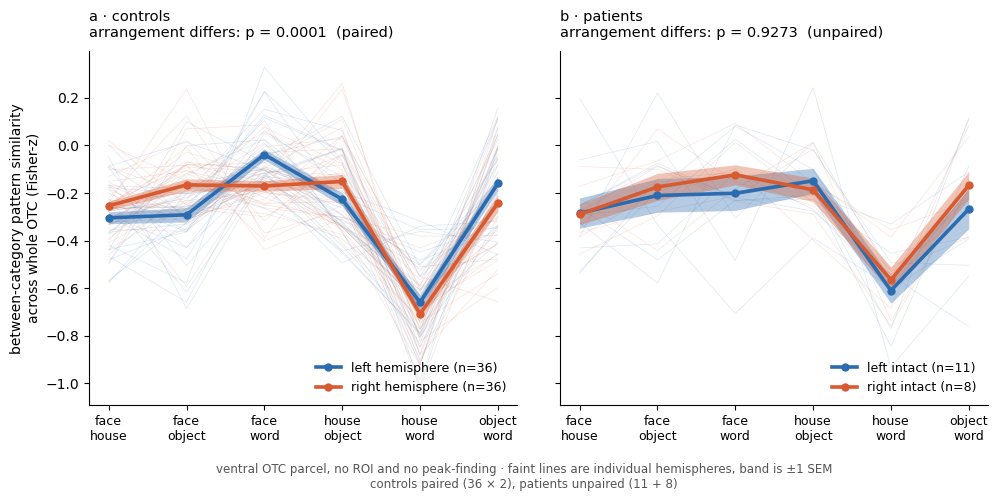

saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/figures/whole_otc_ventral_profiles_11-8.png


In [17]:
# ─── Whole-OTC geometry: controls' hemispheres differ, patients' do not ─────
# Needs M_CH, IDX_CH, ch from the side-typicality cell.
# Source: WOTC_CSV (ventral parcel), via the setup cell above

PAIR_LBL = ['face\nhouse', 'face\nobject', 'face\nword',
            'house\nobject', 'house\nword', 'object\nword']
PAIRS_17 = [c for c in ch.columns if '-' in c]

# ─── COLOR PALETTE (Directly from Figure 1 Variables) ───────────────────────
C_SCAN = "#2B6CB0"  # Steel Blue (Left hemisphere / LH-intact)
C_SURG = "#D85A30"  # Terracotta Orange (Right hemisphere / RH-intact)

CL17, CR17 = C_SCAN, C_SURG  # Controls: Left (Blue) vs Right (Orange)
PL17, PR17 = C_SCAN, C_SURG  # Patients: LH-intact (Blue) vs RH-intact (Orange)

rng17 = np.random.default_rng(31)
NPERM17 = 10000


def _interaction(sa, sb, paired):
    """Does the SHAPE of the six-pair profile differ between two sets?"""
    A, B = M_CH[IDX_CH[sa]], M_CH[IDX_CH[sb]]

    def stat(d):
        return float(((d - d.mean()) ** 2).sum())

    if paired:
        ida = ch['subject_id'].to_numpy()[IDX_CH[sa]]
        idb = ch['subject_id'].to_numpy()[IDX_CH[sb]]
        A, B = A[np.argsort(ida)], B[np.argsort(idb)]
        D = A - B
        obs = stat(D.mean(0))
        null = np.array([stat((D * rng17.choice([-1, 1], len(D))[:, None]).mean(0))
                         for _ in range(NPERM17)])
    else:
        obs = stat(A.mean(0) - B.mean(0))
        pool, na = np.vstack([A, B]), len(A)
        null = np.empty(NPERM17)
        for b in range(NPERM17):
            p = rng17.permutation(len(pool))
            null[b] = stat(pool[p[:na]].mean(0) - pool[p[na:]].mean(0))
    return obs, (np.sum(null >= obs) + 1) / (NPERM17 + 1)


fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.6), sharey=True,
                         gridspec_kw=dict(wspace=0.10))

for ax, (sa, sb, ca, cb, la, lb, ttl) in zip(axes, [
        ('ctl_L', 'ctl_R', CL17, CR17, 'left hemisphere', 'right hemisphere',
         'a \u00b7 controls'),
        ('pt_L', 'pt_R', PL17, PR17, PT_LEGEND[0], PT_LEGEND[1],
         'b \u00b7 patients')]):
    for s, col, lab in ((sa, ca, la), (sb, cb, lb)):
        X = M_CH[IDX_CH[s]]
        m, se = X.mean(0), X.std(0, ddof=1) / np.sqrt(len(X))
        for row in X:
            ax.plot(range(6), row, color=col, lw=.5, alpha=.16, zorder=1)
        ax.fill_between(range(6), m - se, m + se, color=col, alpha=.35, lw=0, zorder=2)
        ax.plot(range(6), m, color=col, lw=2.6, marker='o', ms=5,
                label=f'{lab} (n={len(X)})', zorder=3)
    obs, pv = _interaction(sa, sb, paired=sa.startswith('ctl'))
    ax.set_title(f'{ttl}\narrangement differs: p = {pv:.4f}'
                 + ('  (paired)' if sa.startswith('ctl') else '  (unpaired)'),
                 loc='left', fontsize=10.5, pad=10)
    ax.set_xticks(range(6)); ax.set_xticklabels(PAIR_LBL, fontsize=9)
    ax.legend(fontsize=9, frameon=False, loc='lower right')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    print(f'{ttl}: statistic = {obs:.4f}, p = {pv:.5f}')

axes[0].set_ylabel('between-category pattern similarity\nacross whole OTC (Fisher-z)',
                   fontsize=10)
fig.text(0.5, -0.07,
         'ventral OTC parcel, no ROI and no peak-finding \u00b7 faint lines are individual '
         'hemispheres, band is \u00b11 SEM\n'
         f'controls paired ({len(IDX_CH["ctl_L"])} \u00d7 2), patients unpaired '
         f'({len(IDX_CH["pt_L"])} + {len(IDX_CH["pt_R"])})', ha='center', fontsize=8.5, color='#555')
out17 = FIG_DIR / 'whole_otc_ventral_profiles_11-8.png'
plt.savefig(out17, dpi=300, bbox_inches='tight')
plt.show()
print('saved', out17)

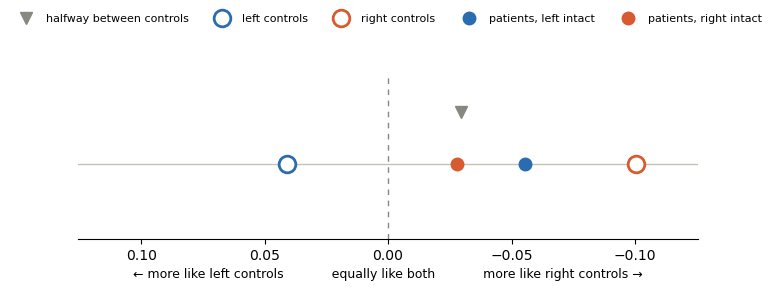

{'left controls': 0.041, 'patients, left intact': -0.056, 'right controls': -0.1, 'patients, right intact': -0.028} | halfway -0.03
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/figures/whole_otc_ventral_positions_11-8.png


In [18]:
# ─── Whole OTC: where each group sits between left and right controls ────────
# Position = mean r with left controls minus mean r with right controls (raw profiles,
# same-subject pairs dropped), averaged per group: own-side typicality, sign-flipped for
# the right-side groups so every group sits on one axis. Positions only; no test here.
POS = {s: float(TYP_RAW_CH[IDX_CH[s]].mean()) * (1 if s.endswith('L') else -1) for s in SETS_CH}
_mid = (POS['ctl_L'] + POS['ctl_R']) / 2
_lab = {'ctl_L': 'left controls', 'ctl_R': 'right controls',
        'pt_L': f'patients, {PT_LEGEND[0]}', 'pt_R': f'patients, {PT_LEGEND[1]}'}
fig, ax = plt.subplots(figsize=(8, 2.1))
ax.axhline(0, color='#c3c2b7', lw=1, zorder=0)
ax.axvline(0, color='#888780', lw=1, ls=(0, (4, 4)), zorder=0)
ax.plot([_mid], [0.42], marker='v', color='#888780', ms=8, ls='none', label='halfway between controls')
for s, col, filled in [('ctl_L', C_SCAN, False), ('ctl_R', C_SURG, False),
                       ('pt_L', C_SCAN, True), ('pt_R', C_SURG, True)]:
    ax.plot([POS[s]], [0], marker='o', ls='none', ms=8 if filled else 12, label=_lab[s], zorder=3 if filled else 2,
            markerfacecolor=col if filled else 'white', markeredgecolor=col, markeredgewidth=2)
_span = max(abs(v) for v in POS.values()) * 1.25
ax.set_xlim(-_span, _span); ax.invert_xaxis(); ax.set_ylim(-0.6, 0.7); ax.set_yticks([])
for sp in ('left', 'top', 'right'):
    ax.spines[sp].set_visible(False)
ax.set_xlabel('\u2190 more like left controls            equally like both            more like right controls \u2192', fontsize=9)
ax.legend(frameon=False, fontsize=8, ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.45))
out18 = FIG_DIR / 'whole_otc_ventral_positions_11-8.png'
plt.savefig(out18, dpi=300, bbox_inches='tight'); plt.show()
print({_lab[s]: round(v, 3) for s, v in POS.items()}, '| halfway', round(_mid, 3)); print('saved', out18)


## 5 · Bayes factors and evidence ratios
The sampled evidence ratios need bambi/pymc (fmri env) and take minutes per model.

In [19]:
# Ported unchanged from 02_whole_otc_bayes.ipynb; runs on this notebook's cohort.
# ─── Bayes factors for the paper's nulls ────────────────────────────────────
# Two reusable functions plus a demonstration on the whole-OTC data.
#
#   bf10_jzs(...)     exact JZS default Bayes factor for one- and two-sample
#                     t tests (Rouder, Speckman, Sun, Morey & Iverson 2009,
#                     Psychon Bull Rev 16:225-237), r = 0.707.
#   bf_incl_bic(...)  Bayes factor for including an interaction, from the BIC
#                     approximation BF10 = exp((BIC_null - BIC_full) / 2)
#                     (Wagenmakers 2007, Psychon Bull Rev 14:779-804). This is
#                     an APPROXIMATION to the BF_incl that a Bayesian ANOVA
#                     returns; it uses subject fixed effects in place of a
#                     random intercept. Report it as such, or recompute with
#                     JASP / the BayesFactor package if an exact value is needed.
#
# Convention (Weber et al. 2026): BF10 < 1/3 is moderate evidence FOR the null,
# BF10 > 3 is moderate evidence against it, and 1/3 to 3 is inconclusive.
#
# To apply this to the manuscript's own nulls, point the same two functions at
# the harmonized per-subject files:
#   D_liu/rsa_v1_harmonized.csv             preferred- and between-category
#   D_liu/univariate_v1_harmonized_sqrt.csv peak selectivity, voxel counts
#   wta_percentages.csv                     WTA composition
# every patient-vs-patient contrast in those files is a two-group mean
# comparison, so bf10_jzs(..., paired=False) applies directly.

from scipy import integrate


def bf10_jzs(x, y=None, paired=False, r=0.707):
    """JZS default BF10. One sample vs 0, paired differences, or two groups."""
    x = np.asarray(x, float)
    if y is None:
        d = x
    elif paired:
        d = x - np.asarray(y, float)
    else:
        y = np.asarray(y, float)
        n1, n2 = len(x), len(y)
        sp = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1))
                     / (n1 + n2 - 2))
        t = (x.mean() - y.mean()) / (sp * np.sqrt(1 / n1 + 1 / n2))
        n_eff, v = n1 * n2 / (n1 + n2), n1 + n2 - 2
        return _bf_from_t(t, n_eff, v, r)
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    return _bf_from_t(t, len(d), len(d) - 1, r)


def _bf_from_t(t, n_eff, v, r):
    def num(g):
        return ((1 + n_eff * g) ** -0.5
                * (1 + t ** 2 / ((1 + n_eff * g) * v)) ** (-(v + 1) / 2)
                * (r ** 2 / 2) ** 0.5 / np.sqrt(np.pi) * g ** -1.5
                * np.exp(-r ** 2 / (2 * g)))
    return integrate.quad(num, 0, np.inf)[0] / (1 + t ** 2 / v) ** (-(v + 1) / 2)


def bf_incl_bic(y, factors, interaction):
    """BIC-approximated BF for including `interaction`, given a dict of
    categorical factors. Each factor is dummy-coded; `interaction` is a tuple of
    two factor names whose product terms are added to the full model."""
    def design(keys, inter=None):
        cols = [np.ones(len(y))]
        for k in keys:
            lv = np.unique(factors[k])[1:]
            cols += [(factors[k] == l).astype(float) for l in lv]
        if inter:
            a, b = inter
            for la in np.unique(factors[a])[1:]:
                for lb in np.unique(factors[b])[1:]:
                    cols.append(((factors[a] == la) & (factors[b] == lb)).astype(float))
        return np.column_stack(cols)

    def bic(X):
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        rss = float(((y - X @ beta) ** 2).sum())
        n, k = len(y), np.linalg.matrix_rank(X)
        return n * np.log(rss / n) + k * np.log(n)

    keys = list(factors)
    return float(np.exp((bic(design(keys)) - bic(design(keys, interaction))) / 2))


def _label(bf):
    return ('moderate evidence FOR the null' if bf < 1 / 3 else
            'evidence AGAINST the null' if bf > 3 else 'inconclusive')


# ---- demonstration on the whole-OTC six-value profiles ---------------------
PAIRS_18 = [c for c in ch.columns if '-' in c]
sid_18 = ch['subject_id'].to_numpy()

print('1. PROFILE-SHAPE INTERACTION  (pair x group, BIC approximation)')
for sa, sb, lab, paired in [('ctl_L', 'ctl_R', 'LH ctrl vs RH ctrl', True),
                            ('pt_L', 'pt_R', 'LH-intact vs RH-intact', False)]:
    idx = np.concatenate([IDX_CH[sa], IDX_CH[sb]])
    grp = np.concatenate([np.zeros(len(IDX_CH[sa])), np.ones(len(IDX_CH[sb]))])
    y = M_CH[idx].ravel()
    fac = dict(pair=np.tile(np.arange(6), len(idx)).astype(float),
               grp=np.repeat(grp, 6),
               sid=np.repeat(np.searchsorted(np.unique(sid_18[idx]), sid_18[idx]), 6)
               .astype(float))
    bf = bf_incl_bic(y, fac, ('pair', 'grp'))
    print(f'   {lab:24s} BF_incl = {bf:.3g}   {_label(bf)}'
          + ('   (paired design)' if paired else ''))

print('\n2. PER-PAIR SCALAR CONTRASTS  (exact JZS BF10)')
print(f'   {"pair":14s} {"ctrl L vs R":>16s} {"pt L vs R":>16s}')
for j, p in enumerate(PAIRS_18):
    cl = M_CH[IDX_CH['ctl_L']][:, j]
    cr = M_CH[IDX_CH['ctl_R']][:, j]
    o = np.argsort(sid_18[IDX_CH['ctl_L']]), np.argsort(sid_18[IDX_CH['ctl_R']])
    bf_c = bf10_jzs(cl[o[0]], cr[o[1]], paired=True)
    bf_p = bf10_jzs(M_CH[IDX_CH['pt_L']][:, j], M_CH[IDX_CH['pt_R']][:, j])
    print(f'   {p:14s} {bf_c:16.3g} {bf_p:16.3g}')

print('\n3. SIDE TYPICALITY vs 0  (exact JZS BF10)')
for s in ['ctl_L', 'ctl_R', 'pt_L', 'pt_R']:
    v = TYP_RAW_CH[IDX_CH[s]]
    bf = bf10_jzs(v)
    print(f'   {s:6s} n={len(v):2d}  mean {v.mean():+.3f}  BF10 = {bf:.3g}   {_label(bf)}')


1. PROFILE-SHAPE INTERACTION  (pair x group, BIC approximation)
   LH ctrl vs RH ctrl       BF_incl = 11.2   evidence AGAINST the null   (paired design)
   LH-intact vs RH-intact   BF_incl = 1.81e-05   moderate evidence FOR the null

2. PER-PAIR SCALAR CONTRASTS  (exact JZS BF10)
   pair                ctrl L vs R        pt L vs R
   face-house                 1.45            0.408
   face-object                 199            0.428
   face-word              2.33e+04            0.519
   house-object               5.05            0.446
   house-word                 1.07            0.459
   object-word                1.79            0.542

3. SIDE TYPICALITY vs 0  (exact JZS BF10)
   ctl_L  n=36  mean +0.041  BF10 = 23.2   evidence AGAINST the null
   ctl_R  n=36  mean +0.100  BF10 = 5.87e+03   evidence AGAINST the null
   pt_L   n=11  mean -0.056  BF10 = 0.485   inconclusive
   pt_R   n= 8  mean +0.028  BF10 = 0.389   inconclusive


In [20]:
# Ported unchanged from 02_whole_otc_bayes.ipynb; runs on this notebook's cohort.
# ─── Bayes factors for every patient-vs-patient null in the paper ───────────
# Needs from earlier cells: REPO, EXCLUDE, EXCLUDE_SES, load_harmonized, np, pd.
# Needs bf10_jzs and bf_incl_bic from the Bayes-factor cell.
#
# Every patient-vs-patient contrast in the manuscript is a two-group mean
# comparison between LH-intact and RH-intact patients in their own intact
# hemisphere, so the exact JZS BF10 applies. The two interactions
# (category x intact-hemisphere, pair x group) use the BIC approximation and are
# labelled as approximate.
#
# Convention (Weber et al. 2026): BF10 < 1/3 moderate evidence FOR the null,
# > 3 moderate evidence against, 1/3 to 3 inconclusive.
# WTA is not included: that measure was cut.
#
# Writes nothing unless --csv style saving is added deliberately.

# house_PPA_strict is the reported ROI for every measure except peak location,
# which uses house_PPA
ROIS_19 = ['word_VWFA', 'face_FFA', 'house_PPA_strict', 'object_LOC']
PAIRS_19 = ['face-word', 'face-house', 'face-object',
            'house-word', 'house-object', 'object-word']


def _lab(bf):
    return ('FOR null' if bf < 1 / 3 else 'against null' if bf > 3 else 'inconclusive')


def _pt_vals(d, col, roi, intact, pair=None):
    m = (d['category'] == roi) & (d['intact_hemi'] == intact)
    if pair is not None:
        m &= (d['pair'] == pair)
    return d.loc[m, col].dropna().to_numpy(float)


# reuse the frames loaded in setup; the collapsed RSA frame is derived here
_rsa19c_pt = rsa_p_long.drop(columns=['pair', 'fisher_r'],
                             errors='ignore').drop_duplicates()
PT19 = {'univ': peak_p, 'rsa': rsa_p_long, 'rsac': _rsa19c_pt}

rows19 = []
print('PATIENT vs PATIENT: exact JZS BF10  (LH-intact vs RH-intact)')
for src, col, meas in [('univ', 'peak_z', 'peak selectivity'),
                       ('univ', 'volume', 'selective voxel count'),
                       ('rsac', 'liu_distinctiveness', 'preferred-category similarity')]:
    print(f'\n  {meas}')
    for roi in ROIS_19:
        a = _pt_vals(PT19[src], col, roi, 'left')
        b = _pt_vals(PT19[src], col, roi, 'right')
        if len(a) < 3 or len(b) < 3:
            print(f'    {roi:12s} n={len(a)}/{len(b)}  too few'); continue
        bf = bf10_jzs(a, b)
        rows19.append(dict(measure=meas, roi=roi, pair='', bf10=bf))
        print(f'    {roi:12s} n={len(a)}/{len(b)}  '
              f'{a.mean():+.3f} vs {b.mean():+.3f}  BF10={bf:.3g}  {_lab(bf)}')

print('\n  between-category similarity, per ROI x pair')
for roi in ROIS_19:
    for p in PAIRS_19:
        a = _pt_vals(PT19['rsa'], 'fisher_r', roi, 'left', p)
        b = _pt_vals(PT19['rsa'], 'fisher_r', roi, 'right', p)
        if len(a) < 3 or len(b) < 3:
            continue
        bf = bf10_jzs(a, b)
        rows19.append(dict(measure='between-category similarity', roi=roi,
                           pair=p, bf10=bf))
        print(f'    {roi:12s} {p:14s} BF10={bf:.3g}  {_lab(bf)}')

print('\nINTERACTIONS: BIC approximation, report as approximate')
d = PT19['univ']
for col, meas in [('peak_z', 'peak selectivity'), ('volume', 'voxel count')]:
    s = d[d['category'].isin(ROIS_19)].dropna(subset=[col])
    bf = bf_incl_bic(s[col].to_numpy(float),
                     dict(cat=s['category'].to_numpy(),
                          grp=s['intact_hemi'].to_numpy()), ('cat', 'grp'))
    print(f'  category x intact-hemi, {meas:22s} BF_incl ~ {bf:.3g}  {_lab(bf)}')
s = PT19['rsac'][PT19['rsac']['category'].isin(ROIS_19)].dropna(
    subset=['liu_distinctiveness'])
bf = bf_incl_bic(s['liu_distinctiveness'].to_numpy(float),
                 dict(cat=s['category'].to_numpy(),
                      grp=s['intact_hemi'].to_numpy()), ('cat', 'grp'))
print(f'  category x intact-hemi, preferred-cat similarity  BF_incl ~ {bf:.3g}  {_lab(bf)}')
for roi in ROIS_19:
    s = PT19['rsa'][(PT19['rsa']['category'] == roi)].dropna(subset=['fisher_r'])
    if s['intact_hemi'].nunique() < 2:
        continue
    bf = bf_incl_bic(s['fisher_r'].to_numpy(float),
                     dict(pair=s['pair'].to_numpy(),
                          grp=s['intact_hemi'].to_numpy()), ('pair', 'grp'))
    print(f'  pair x group, {roi:12s}                      BF_incl ~ {bf:.3g}  {_lab(bf)}')

BF19 = pd.DataFrame(rows19)
print(f'\n{len(BF19)} scalar contrasts | '
      f'{(BF19.bf10 < 1/3).sum()} favour the null, '
      f'{(BF19.bf10 > 3).sum()} favour a difference, '
      f'{((BF19.bf10 >= 1/3) & (BF19.bf10 <= 3)).sum()} inconclusive')


PATIENT vs PATIENT: exact JZS BF10  (LH-intact vs RH-intact)

  peak selectivity
    word_VWFA    n=11/8  +5.291 vs +5.862  BF10=0.469  inconclusive
    face_FFA     n=11/8  +6.943 vs +7.723  BF10=0.487  inconclusive
    house_PPA_strict n=11/8  +4.432 vs +4.823  BF10=0.447  inconclusive
    object_LOC   n=11/8  +8.361 vs +9.259  BF10=0.485  inconclusive

  selective voxel count
    word_VWFA    n=11/8  +11.037 vs +15.172  BF10=0.734  inconclusive
    face_FFA     n=11/8  +17.995 vs +22.291  BF10=0.701  inconclusive
    house_PPA_strict n=11/8  +7.927 vs +6.735  BF10=0.463  inconclusive
    object_LOC   n=11/8  +57.881 vs +58.209  BF10=0.408  inconclusive

  preferred-category similarity
    word_VWFA    n=11/8  +0.617 vs +0.643  BF10=0.411  inconclusive
    face_FFA     n=11/8  +0.607 vs +0.528  BF10=0.48  inconclusive
    house_PPA_strict n=11/8  +0.249 vs +0.251  BF10=0.408  inconclusive
    object_LOC   n=11/8  +1.215 vs +1.325  BF10=0.439  inconclusive

  between-category similari

In [21]:
# Ported unchanged from 02_whole_otc_bayes.ipynb; runs on this notebook's cohort.
# ─── Sampled mixed-model BF_incl, replacing the BIC approximation ──────────
# Install once on the cluster:
#     pip install bambi --user
# (bambi pulls pymc and arviz.)
#
# The BIC approximation in the Bayes-factor cell substitutes subject fixed
# effects for a random intercept and is known to be extreme in the tails, so its
# 1e-05 values should not be quoted. This computes the inclusion Bayes factor
# by comparing two models that differ only in the interaction term, each with a
# subject random intercept, using bridge sampling of the marginal likelihood.
#
# Needs PT19 from the Bayes-factor cell (patients only, cohort of record).
# Runtime is minutes per model, so run it once and keep the table.
# ─── bambi: install into this kernel's environment if missing ────────────────
import sys, subprocess, importlib.util
import numpy as _np
print('kernel python:', sys.executable, '| numpy', _np.__version__)
if importlib.util.find_spec('bambi') is None:
    _cmd = [sys.executable, '-m', 'pip', 'install', 'bambi']
    if subprocess.call(_cmd) != 0:              # env not writable -> user site
        subprocess.check_call(_cmd + ['--user'])
    subprocess.run([sys.executable, '-c', 'import numpy; print("numpy now", numpy.__version__)'])
    raise SystemExit('bambi installed: restart the kernel, then Run All.')

import bambi as bmb
import arviz as az
import numpy as np
import pandas as pd

ROIS_21 = ['word_VWFA', 'face_FFA', 'house_PPA_strict', 'object_LOC']
DRAWS, TUNE, CHAINS = 4000, 2000, 4


def bf_incl_sampled(df, y, f1, f2, sid='subject_id'):
    """BF for including f1:f2, by marginal likelihood ratio of two models that
    differ only in that term. Both carry a random intercept for subject."""
    d = df[[y, f1, f2, sid]].dropna().copy()
    for c in (f1, f2):
        d[c] = d[c].astype('category')
    out = {}
    for name, formula in (('full', f'{y} ~ {f1} * {f2} + (1|{sid})'),
                          ('null', f'{y} ~ {f1} + {f2} + (1|{sid})')):
        m = bmb.Model(formula, d)
        idata = m.fit(draws=DRAWS, tune=TUNE, chains=CHAINS,
                      idata_kwargs={'log_likelihood': True},
                      progressbar=False, random_seed=42)
        out[name] = idata
    # PSIS-LOO difference as the model-comparison statistic, then convert to a
    # Bayes-factor-scale quantity. elpd_diff is on the log scale, so exp() of
    # the difference is the evidence ratio.
    cmp = az.compare({'full': out['full'], 'null': out['null']}, ic='loo')
    elpd = cmp['elpd_loo']
    return float(np.exp(elpd['full'] - elpd['null'])), cmp


rows21 = []
print('SAMPLED BF_incl  (bridge/LOO evidence ratio, subject random intercept)')
print('  category x intact-hemisphere')
for src, col, lab in [('univ', 'peak_z', 'peak selectivity'),
                      ('univ', 'volume', 'selective voxel count'),
                      ('rsac', 'liu_distinctiveness', 'preferred-category similarity')]:
    d = PT19[src]
    d = d[d['category'].isin(ROIS_21)]
    bf, cmp = bf_incl_sampled(d, col, 'category', 'intact_hemi')
    rows21.append(dict(test=f'category x intact-hemi | {lab}', bf_incl=bf))
    print(f'    {lab:32s} BF_incl = {bf:.3g}')

print('  pair x group, per ROI')
for roi in ROIS_21:
    d = PT19['rsa']
    d = d[d['category'] == roi]
    if d['intact_hemi'].nunique() < 2:
        continue
    bf, cmp = bf_incl_sampled(d, 'fisher_r', 'pair', 'intact_hemi')
    rows21.append(dict(test=f'pair x group | {roi}', bf_incl=bf))
    print(f'    {roi:32s} BF_incl = {bf:.3g}')

BF21 = pd.DataFrame(rows21)
print('\nCompare against the BIC approximation. Large disagreement means the')
print('approximation was doing the work, and only these values should be quoted.')
print(BF21.to_string(index=False))


kernel python: /home/csimmon2/anaconda3/envs/fmri/bin/python | numpy 1.26.4
SAMPLED BF_incl  (bridge/LOO evidence ratio, subject random intercept)
  category x intact-hemisphere


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, intact_hemi, category:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 30 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 22 seconds.
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:803: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and L

    peak selectivity                 BF_incl = 0.0212


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [volume_sigma, Intercept, category, intact_hemi, category:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 32 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [volume_sigma, Intercept, category, intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 29 seconds.
There were 4 divergences after tuning. Increase `target_accept` or reparameterize.
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:803: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is beca

    selective voxel count            BF_incl = 0.0288


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [liu_distinctiveness_sigma, Intercept, category, intact_hemi, category:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 28 seconds.
There were 8 divergences after tuning. Increase `target_accept` or reparameterize.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [liu_distinctiveness_sigma, Intercept, category, intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 24 seconds.
There were 9 divergences after tuning. Increase `target_accept` or reparameterize.
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:803: UserWarning: Estimated shape parameter of Pareto distribu

... (6 outputs left out)

    house_PPA_strict                 BF_incl = 0.00277


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [fisher_r_sigma, Intercept, pair, intact_hemi, pair:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 45 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [fisher_r_sigma, Intercept, pair, intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 29 seconds.
There were 1 divergences after tuning. Increase `target_accept` or reparameterize.


    object_LOC                       BF_incl = 0.0429

Compare against the BIC approximation. Large disagreement means the
approximation was doing the work, and only these values should be quoted.
                                                  test  bf_incl
             category x intact-hemi | peak selectivity 0.021175
        category x intact-hemi | selective voxel count 0.028781
category x intact-hemi | preferred-category similarity 0.026165
                              pair x group | word_VWFA 0.190871
                               pair x group | face_FFA 0.032816
                       pair x group | house_PPA_strict 0.002773
                             pair x group | object_LOC 0.042933


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (


In [22]:
# Ported unchanged from 02_whole_otc_bayes.ipynb; runs on this notebook's cohort.
# ─── Sampled interaction evidence ratios for the CONTROL comparison ────────
# Companion to the patient-versus-patient version. Needs bambi/pymc, plus
# peak_c, vox_c, rsa_c_long from 5_figures/01_final_figures.ipynb.
#
# Controls contribute both hemispheres, so hemisphere is a within-subject
# factor here, unlike the patient comparison where the two groups are different
# people. The random intercept for subject therefore does more work: it absorbs
# each control's overall level, and the interaction asks whether the profile
# across categories (or pairs) differs between that subject's two hemispheres.
#
# Same quantity as the patient version: two mixed models differing only in the
# interaction term, compared by leave-one-out expected log predictive density,
# exponentiated onto the Bayes-factor scale. Strictly an evidence ratio, not a
# marginal-likelihood BF_incl.
#
# Convention: below 1/3 evidence for no difference, above 3 for a difference.

import bambi as bmb
import arviz as az

ROIS_24 = ['word_VWFA', 'face_FFA', 'house_PPA_strict', 'object_LOC']
DRAWS24, TUNE24, CHAINS24 = 4000, 2000, 4


def _er_sampled(d, y, f1, f2, sid='subject_id'):
    d = d[[y, f1, f2, sid]].dropna().copy()
    for c in (f1, f2):
        d[c] = d[c].astype('category')
    fits = {}
    for name, formula in (('full', f'{y} ~ {f1} * {f2} + (1|{sid})'),
                          ('null', f'{y} ~ {f1} + {f2} + (1|{sid})')):
        fits[name] = bmb.Model(formula, d).fit(
            draws=DRAWS24, tune=TUNE24, chains=CHAINS24,
            idata_kwargs={'log_likelihood': True},
            progressbar=False, random_seed=42)
    cmp = az.compare(fits, ic='loo')['elpd_loo']
    return float(np.exp(cmp['full'] - cmp['null']))


rows24 = []
print('CONTROLS, left versus right: sampled interaction evidence ratios')
print('  category x hemisphere')
for cdf, col, lab in [
        (peak_c, 'peak_z', 'peak selectivity'),
        (vox_c, 'volume', 'selective voxel count'),
        (rsa_c_long.drop_duplicates(['subject_id', 'category', 'hemi']),
         'liu_distinctiveness', 'preferred-category similarity')]:
    d = cdf[cdf['category'].isin(ROIS_24)]
    er = _er_sampled(d, col, 'category', 'hemi')
    rows24.append(dict(test=f'category x hemi | {lab}', er=er))
    print(f'    {lab:32s} ER = {er:.3g}')

print('  pair x hemisphere, per ROI')
for roi in ROIS_24:
    d = rsa_c_long[rsa_c_long['category'] == roi]
    er = _er_sampled(d, 'fisher_r', 'pair', 'hemi')
    rows24.append(dict(test=f'pair x hemi | {roi}', er=er))
    print(f'    {roi:32s} ER = {er:.3g}')

CTRL_ER = pd.DataFrame(rows24)
print('\nPaste these into CONTROL_INTERACTION_BF / CTRL_PAIR_BF_BY_ROI in the')
print('per-ROI line figure cell so both comparisons carry an interaction term.')
print(CTRL_ER.to_string(index=False))


CONTROLS, left versus right: sampled interaction evidence ratios
  category x hemisphere


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, hemi, category:hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 53 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 39 seconds.
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWar

    peak selectivity                 ER = 3.91e+03


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [volume_sigma, Intercept, category, hemi, category:hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 31 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [volume_sigma, Intercept, category, hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 46 seconds.
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anacond

    selective voxel count            ER = 1.66e+03


... (7 outputs left out)

    house_PPA_strict                 ER = 9.47


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [fisher_r_sigma, Intercept, pair, hemi, pair:hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 36 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [fisher_r_sigma, Intercept, pair, hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 42 seconds.


    object_LOC                       ER = 269

Paste these into CONTROL_INTERACTION_BF / CTRL_PAIR_BF_BY_ROI in the
per-ROI line figure cell so both comparisons carry an interaction term.
                                           test          er
             category x hemi | peak selectivity 3911.023898
        category x hemi | selective voxel count 1661.841191
category x hemi | preferred-category similarity    8.896908
                        pair x hemi | word_VWFA 8142.474685
                         pair x hemi | face_FFA 3069.252035
                 pair x hemi | house_PPA_strict    9.469828
                       pair x hemi | object_LOC  268.823834


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (


## 6 · Not included
- **TFCE and peak location:** not rerun for this cohort.
- **Laterality-gradient tables (Tables 2 and 4) and the single peak model:** come from the grid scripts, not reproduced here.

In [23]:
# ─── Sampled interaction evidence ratios: controls and patients (fmri kernel) ─
# Replaces both bambi cells; same models and settings as 02_whole_otc_bayes. Two mixed
# models differing only in the interaction, each with a subject random intercept,
# compared by leave-one-out expected log predictive density; exp(difference) is the
# evidence ratio (below 1/3 favours no difference, above 3 a difference). Controls: left
# vs right hemisphere, within subject. Patients: LH-intact vs RH-intact, between subjects.
# Needs PT19 from the Bayes-factor cell. Slow (14 model pairs); the table is saved to OUT.
import bambi as bmb
import arviz as az

ER_ROIS = ['word_VWFA', 'face_FFA', 'house_PPA_strict', 'object_LOC']
DRAWS, TUNE, CHAINS = 4000, 2000, 4

def _er_sampled(d, y, f1, f2, sid='subject_id'):
    d = d[[y, f1, f2, sid]].dropna().copy()
    for c in (f1, f2):
        d[c] = d[c].astype('category')
    fits = {name: bmb.Model(f, d).fit(draws=DRAWS, tune=TUNE, chains=CHAINS,
                                      idata_kwargs={'log_likelihood': True},
                                      progressbar=False, random_seed=42)
            for name, f in (('full', f'{y} ~ {f1} * {f2} + (1|{sid})'),
                            ('null', f'{y} ~ {f1} + {f2} + (1|{sid})'))}
    t = az.compare(fits, ic='loo', scale='log')
    e = t['elpd_loo' if 'elpd_loo' in t.columns else 'loo']
    return float(np.exp(e['full'] - e['null']))

_rsac_c = rsa_c_long.drop_duplicates(['subject_id', 'category', 'hemi'])
_jobs = []
for lab, ct, pt, y in [('peak selectivity', peak_c, PT19['univ'], 'peak_z'),
                       ('selective voxel count', vox_c, PT19['univ'], 'volume'),
                       ('preferred-category similarity', _rsac_c, PT19['rsac'], 'liu_distinctiveness')]:
    _jobs += [('controls', f'category x hemisphere | {lab}', ct[ct['category'].isin(ER_ROIS)], y, 'category', 'hemi'),
              ('patients', f'category x hemisphere | {lab}', pt[pt['category'].isin(ER_ROIS)], y, 'category', 'intact_hemi')]
for roi in ER_ROIS:
    _jobs += [('controls', f'pair x hemisphere | {ROI_TITLE[roi]}', rsa_c_long[rsa_c_long['category'] == roi], 'fisher_r', 'pair', 'hemi'),
              ('patients', f'pair x hemisphere | {ROI_TITLE[roi]}', PT19['rsa'][PT19['rsa']['category'] == roi], 'fisher_r', 'pair', 'intact_hemi')]

_rows = []
for grp, test, d, y, f1, f2 in _jobs:
    er = _er_sampled(d, y, f1, f2)
    _rows.append(dict(test=test, group=grp, n_subjects=d['subject_id'].nunique(), evidence_ratio=er))
    print(f'{test:48s} {grp:9s} ER = {er:.3g}', flush=True)
ER_TABLE = pd.DataFrame(_rows)
ER_TABLE.to_csv(OUT / 'evidence_ratios_11-8.csv', index=False)
print('saved', OUT / 'evidence_ratios_11-8.csv')

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, hemi, category:hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 29 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 31 seconds.


category x hemisphere | peak selectivity         controls  ER = 3.91e+03


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [peak_z_sigma, Intercept, category, intact_hemi, category:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) too

category x hemisphere | peak selectivity         patients  ER = 0.0212


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [volume_sigma, Intercept, category, hemi, category:hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 53 seconds.


category x hemisphere | selective voxel count    controls  ER = 1.66e+03


... (19 outputs left out)

pair x hemisphere | LO                           controls  ER = 269


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [fisher_r_sigma, Intercept, pair, intact_hemi, pair:intact_hemi, 1|subject_id_sigma, 1|subject_id_offset]
Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 62 s

pair x hemisphere | LO                           patients  ER = 0.0429
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/evidence_ratios_11-8.csv


/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (
/home/csimmon2/anaconda3/envs/fmri/lib/python3.9/site-packages/arviz/stats/stats.py:307: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'log' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_comp.loc[val] = (


In [24]:
# ─── Recheck the four patient fits that warned ───────────────────────────────
# Same models as the cell above, refit with target_accept = 0.95 (default 0.8), which
# removes most divergences. For each model it counts divergences and data points with
# Pareto k > 0.7 (where the leave-one-out shortcut is unreliable), and gives the SE of
# the elpd difference. Needs _jobs and ER_TABLE from the cell above.
import logging, warnings

FLAGGED = [('patients', 'category x hemisphere | peak selectivity'),
           ('patients', 'category x hemisphere | selective voxel count'),
           ('patients', 'category x hemisphere | preferred-category similarity'),
           ('patients', 'pair x hemisphere | LO')]

def _check(d, y, f1, f2, sid='subject_id'):
    d = d[[y, f1, f2, sid]].dropna().copy()
    for c in (f1, f2):
        d[c] = d[c].astype('category')
    fits, r = {}, {'n_obs': len(d)}
    for name, f in (('full', f'{y} ~ {f1} * {f2} + (1|{sid})'),
                    ('null', f'{y} ~ {f1} + {f2} + (1|{sid})')):
        idata = bmb.Model(f, d).fit(draws=DRAWS, tune=TUNE, chains=CHAINS, target_accept=0.95,
                                    idata_kwargs={'log_likelihood': True},
                                    progressbar=False, random_seed=42)
        fits[name] = idata
        r[f'div_{name}'] = int(idata.sample_stats['diverging'].sum())
        r[f'k07_{name}'] = int((az.loo(idata, pointwise=True).pareto_k > 0.7).sum())
    t = az.compare(fits, ic='loo', scale='log')
    e = t['elpd_loo' if 'elpd_loo' in t.columns else 'loo']
    r['er'] = float(np.exp(e['full'] - e['null']))
    r['dse'] = float(t['dse'].max())
    return r

_lvl = logging.getLogger('pymc').level
logging.getLogger('pymc').setLevel(logging.ERROR)
_chk = []
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for grp, test, d, y, f1, f2 in _jobs:
            if (grp, test) not in FLAGGED:
                continue
            r = _check(d, y, f1, f2)
            r0 = ER_TABLE.loc[(ER_TABLE.group == grp) & (ER_TABLE.test == test), 'evidence_ratio'].iloc[0]
            _chk.append(dict(test=test, group=grp, er_first_run=r0, er_recheck=r['er'], **r))
            print(f"{test:52s} ER {r0:.3g} -> {r['er']:.3g} | divergences {r['div_full']}/{r['div_null']}"
                  f" | k>0.7 {r['k07_full']}/{r['k07_null']} of {r['n_obs']} | SE of elpd diff {r['dse']:.2f}", flush=True)
finally:
    logging.getLogger('pymc').setLevel(_lvl)
ER_CHECK = pd.DataFrame(_chk).drop(columns='er')
ER_CHECK.to_csv(OUT / 'evidence_ratios_check_11-8.csv', index=False)
print('saved', OUT / 'evidence_ratios_check_11-8.csv')

category x hemisphere | peak selectivity             ER 0.0212 -> 0.0168 | divergences 0/0 | k>0.7 2/0 of 76 | SE of elpd diff 0.59
category x hemisphere | selective voxel count        ER 0.0288 -> 0.0306 | divergences 0/0 | k>0.7 1/1 of 76 | SE of elpd diff 0.81
category x hemisphere | preferred-category similarity ER 0.0262 -> 0.0505 | divergences 0/0 | k>0.7 1/1 of 76 | SE of elpd diff 1.11
pair x hemisphere | LO                               ER 0.0429 -> 0.0481 | divergences 0/0 | k>0.7 0/0 of 114 | SE of elpd diff 2.57
saved /user_data/csimmon2/git_repos/sym_pt/sandbox/paper_talk_11-8_ventral_2026-11-24/evidence_ratios_check_11-8.csv
